# EDA na Prática

Nas aulas 9 e 10 vimos os quatro princípios da EDA (estrutural, distribucional, relacional e detecção de outliers/anomalias), como tratar dados ausentes e outliers, e como fazer análise descritiva, bivariada e multivariada. Hoje é a hora de **aplicarmos na prática**. Durante a primeira hora da aula, serão apresentadas as técnicas no dataset *Heart Disease* (UCI) e depois **cada aluno** irá aplicar as técnicas no dataset que foi escolhido semana passada.

*Relembrando*: a EDA não é uma linha reta

A EDA costuma ser apresentada como uma sequência de etapas (estrutura → tratamento → descrição → relação), mas na prática ela é **iterativa**: às vezes tratamos um outlier, olhamos a estatística descritiva de novo, e percebemos que precisa voltar atrás. Hoje vamos deixar isso explícito: olhamos a estatística descritiva **antes** de tratar dados ausentes/outliers (pra saber *como* tratar) e **depois** (pra confirmar o efeito do tratamento).

## Como funcionará a atividade

- **Duração:** ~1h40min
- **Formato:** individual
- **Passo 1:** acompanhem a demonstração no dataset Heart Disease.
- **Passo 2:** importem o dataset que vocês escolheram e enviaram anteriormente.
- **Passo 3:** repliquem o mesmo ciclo no dataset escolhido, respondendo às perguntas guiadas.
- **Uso de IA:** permitido, conforme o Plano de Ensino — documentem na seção final.

## Setup de Bibliotecas e Dados

In [2]:
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore", category=FutureWarning)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

COR_NEUTRA = "lightgray"     # convenção: cinza-claro pra tudo que é "pano de fundo" genérico
COR_CONTEXTO = "#e9d4d0"     # rosa-claro pra pano de fundo / classe de referência ("No")
COR_DESTAQUE = "#2d223a"     # roxo pra classe de interesse ("Yes" = tem doença cardíaca)
COR_ALERTA = "tab:red"       # exceção deliberada: outliers/pontos de atenção

PALETA_CLASSE = {"No": COR_CONTEXTO, "Yes": COR_DESTAQUE}
SEED = 42                    # pra amostras reprodutíveis

## Carregando o Dataset

In [3]:
df = pd.read_csv("../data/raw/CVD_cleaned.csv")
df.head()

,General_Health,Checkup,Exercise,Heart_Disease,Skin_Cancer,Other_Cancer,Depression,Diabetes,Arthritis,Sex,Age_Category,Height_(cm),Weight_(kg),BMI,Smoking_History,Alcohol_Consumption,Fruit_Consumption,Green_Vegetables_Consumption,FriedPotato_Consumption
0,Poor,Within the past 2 years,No,No,No,No,No,No,Yes,Female,70-74,150.0,32.66,14.54,Yes,0.0,30.0,16.0,12.0
1,Very Good,Within the past year,No,Yes,No,No,No,Yes,No,Female,70-74,165.0,77.11,28.29,No,0.0,30.0,0.0,4.0
2,Very Good,Within the past year,Yes,No,No,No,No,Yes,No,Female,60-64,163.0,88.45,33.47,No,4.0,12.0,3.0,16.0
3,Poor,Within the past year,Yes,Yes,No,No,No,Yes,No,Male,75-79,180.0,93.44,28.73,No,0.0,30.0,30.0,8.0
4,Good,Within the past year,No,No,No,No,No,No,No,Male,80+,191.0,88.45,24.37,Yes,0.0,8.0,4.0,0.0


## 1. Princípio Estrutural

Antes de qualquer análise, precisamos entender a "anatomia" dos dados: quantas linhas e colunas temos, que tipo de dado cada coluna guarda, se há valores faltantes e se há duplicadas.

**Antes de rodar:** o Heart Disease tem 13 variáveis preditoras (idade, sexo, tipo de dor no peito, pressão em repouso, colesterol, entre outras) mais o alvo (`num`, presença/grau de doença cardíaca). Quantas linhas vocês esperam que um dataset clínico como esse tenha — dezenas, centenas ou milhares de pacientes?

### Dimensão e Tipos de Dados

In [4]:
print(f"Linhas: {df.shape[0]:,} | Colunas: {df.shape[1]}")

Linhas: 308,854 | Colunas: 19


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 308854 entries, 0 to 308853
Data columns (total 19 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   General_Health                308854 non-null  object 
 1   Checkup                       308854 non-null  object 
 2   Exercise                      308854 non-null  object 
 3   Heart_Disease                 308854 non-null  object 
 4   Skin_Cancer                   308854 non-null  object 
 5   Other_Cancer                  308854 non-null  object 
 6   Depression                    308854 non-null  object 
 7   Diabetes                      308854 non-null  object 
 8   Arthritis                     308854 non-null  object 
 9   Sex                           308854 non-null  object 
 10  Age_Category                  308854 non-null  object 
 11  Height_(cm)                   308854 non-null  float64
 12  Weight_(kg)                   308854 non-nul

In [6]:
display(df.describe().T.round(2))
display(df.describe(exclude="number").T)

,count,mean,std,min,25%,50%,75%,max
Height_(cm),308854.0,170.62,10.66,91.00,163.00,170.00,178.00,241.00
Weight_(kg),308854.0,83.59,21.34,24.95,68.04,81.65,95.25,293.02
BMI,308854.0,28.63,6.52,12.02,24.21,27.44,31.85,99.33
Alcohol_Consumption,308854.0,5.10,8.20,0.00,0.00,1.00,6.00,30.00
Fruit_Consumption,308854.0,29.84,24.88,0.00,12.00,30.00,30.00,120.00
Green_Vegetables_Consumption,308854.0,15.11,14.93,0.00,4.00,12.00,20.00,128.00
FriedPotato_Consumption,308854.0,6.30,8.58,0.00,2.00,4.00,8.00,128.00


,count,unique,top,freq
General_Health,308854,5,Very Good,110395
Checkup,308854,5,Within the past year,239371
Exercise,308854,2,Yes,239381
Heart_Disease,308854,2,No,283883
Skin_Cancer,308854,2,No,278860
Other_Cancer,308854,2,No,278976
Depression,308854,2,No,246953
Diabetes,308854,4,No,259141
Arthritis,308854,2,No,207783
Sex,308854,2,Female,160196


### Duplicadas

In [7]:
n_dup = df.duplicated().sum()
print(f"Linhas duplicadas: {n_dup} ({n_dup / len(df):.3%} da base)")

Linhas duplicadas: 80 (0.026% da base)


In [8]:
df = df.drop_duplicates().reset_index(drop=True)
print(f"Linhas após remover duplicadas: {len(df):,}")

Linhas após remover duplicadas: 308,774


## 2. Dados Faltantes

In [9]:
df.isna().sum()

General_Health                  0
Checkup                         0
Exercise                        0
Heart_Disease                   0
Skin_Cancer                     0
Other_Cancer                    0
Depression                      0
Diabetes                        0
Arthritis                       0
Sex                             0
Age_Category                    0
Height_(cm)                     0
Weight_(kg)                     0
BMI                             0
Smoking_History                 0
Alcohol_Consumption             0
Fruit_Consumption               0
Green_Vegetables_Consumption    0
FriedPotato_Consumption         0
dtype: int64

**Discussao:** Alguma feature tem dados ausentes nos seus dados?

*Resposta*: Não. Nenhuma coluna tem `NaN`, pois essa versão do dataset (`CVD_cleaned`) já foi **pré-processada** pelo autor no Kaggle a partir do BRFSS 2021 original. No BRFSS bruto existem códigos como 7 ("não sei") e 9 ("recusou responder"), que viram ausentes. Ou seja, as linhas com ausentes provavelmente foram **removidas antes** de chegarem até nós, e isso é uma limitação importante: não sabemos quem foi excluído, e se a exclusão não foi aleatória (ex.: pessoas mais doentes recusando perguntas), a base pode ter um viés que não conseguimos medir aqui.

#### Identificando o mecanismo de dados ausentes

**Conhecimento de Domínio**

*Como os dados foram coletados:*
- Os dados do BRFSS foram coletados por meio de entrevistas telefônicas com adultos (18+) nos EUA, usando discagem aleatória de números (random digit dialing) — com amostragem estratificada para linhas fixas e amostragem aleatória para celulares. Em domicílios com linha fixa, um morador era sorteado para responder; em celulares, respondia quem atendia. Cada estado americano conduziu suas próprias ligações ao longo do ano, aplicando um questionário padronizado definido com o CDC, e as respostas — todas autorreportadas, não medidas clinicamente — foram depois ponderadas estatisticamente (raking) para corrigir vieses de amostragem e melhor representar a população.

*Qual a natureza da fonte de dados:*
- Dados primários de pesquisa (survey), de natureza observacional e autorreportada — não são registros clínicos, mas respostas que os próprios entrevistados deram sobre sua saúde. É uma base pública, oficial, coletada pelo governo dos EUA (CDC) em parceria com os departamentos de saúde estaduais.

**As ausencias ocorrem juntas?**

Contar ausentes por coluna não conta a história toda: se duas colunas ficam ausentes **nas mesmas linhas**, isso é um indício de padrão sistemático (ex: um exame que não foi feito, afetando várias medidas de uma vez).



In [10]:
cols_com_ausentes = df.columns[df.isna().any()].tolist()
print("Colunas com ausentes:", cols_com_ausentes)

if len(cols_com_ausentes) >= 2:
    tabela_contingencia = pd.crosstab(
        df[cols_com_ausentes[0]].isna(), df[cols_com_ausentes[1]].isna(),
        rownames=[f"{cols_com_ausentes[0]} ausente"], colnames=[f"{cols_com_ausentes[1]} ausente"])
    fig, ax = plt.subplots(figsize=(6, 5))
    sns.heatmap(tabela_contingencia, annot=True, fmt="d", cmap="magma", ax=ax)
    ax.set_title("As ausências ocorrem juntas?")
    plt.tight_layout()
    plt.show()
else:
    print("Menos de duas colunas com ausentes: não há co-ocorrência de ausências para analisar.")

Colunas com ausentes: []
Menos de duas colunas com ausentes: não há co-ocorrência de ausências para analisar.


Com poucos ausentes (no máximo poucas dezenas de linhas), uma correlação entre as colunas de ausência pode parecer precisa, mas na prática é calculada em cima de um poucos de casos, ou seja, número pequeno demais pra confiar no coeficiente. Aqui a contagem bruta (quantas linhas têm as duas ausências ao mesmo tempo) é mais honesta que uma correlação.

**Pra discutir:** quantas linhas têm as duas colunas ausentes ao mesmo tempo? Isso muda a hipótese sobre o mecanismo de ausência (MCAR/MAR/MNAR), ou parecem eventos independentes?

*Relembrando:*
- MCAR: Mecanismo Aleatório e sem viés
- MAR: Mecanismo Randômico e com viés possível de corrigir
- MNAR: Mecanismo Não Randômico relacionada a própria feature

*Resposta*: Como não há ausentes no arquivo, não dá para testar o mecanismo com os dados. Pelo conhecimento de domínio, porém, dá para levantar hipóteses sobre o que foi removido na limpeza original:
- Perguntas sobre **peso** e **consumo de álcool** são sensíveis; quem tem peso muito alto ou bebe muito pode preferir não responder → a ausência dependeria do próprio valor (**MNAR**).
- Ligações interrompidas no meio do questionário afetam várias perguntas do final de uma vez, independentemente do valor → mais próximo de **MCAR/MAR**.

Se as linhas excluídas foram MNAR, a base que temos **subestima** extremos de peso/IMC e de álcool. Fica como limitação registrada.

- *Se supormos que a ausência depende do próprio valor que está faltando*: por exemplo, o paciente não fez o exame porque já se suspeitava (por sinais clínicos observados previamente) que o resultado seria anormal, e o exame extra não seria necessário, isso seria classificado como **MNAR**.
- *Se supormos que a ausência depende de algo externo ao valor em si*: por exemplo, o protocolo de coleta decidiu não solicitar aquele exame, ou o custo do procedimento limitou a coleta, independente do que o resultado provavelmente seria — isso seria classificado como **MAR** (ou até **MCAR**, se a decisão for arbitrária e não sistemática).

Não dá pra decidir entre as duas só olhando os dados — é exatamente o tipo de situação em que testes estatísticos (como o teste de MCAR) e conhecimento de domínio real (falar com quem coletou os dados) resolveriam a dúvida. Na ausência disso, seguimos com a opção mais conservadora na hora de tratar.

**Nota para quando vocês replicarem no dataset de vocês:** se o dataset escolhido tiver *muitas* colunas com *muitos* ausentes, aí sim uma correlação (ou um heatmap) entre os indicadores de ausência passa a fazer sentido. O problema neste caso foi o volume pequeno, não a técnica em si.

## 3. Princípio Distribucional

Ainda com os dados originais (sem tratar ausentes ou outliers), vamos calcular as estatísticas descritivas e olhar as distribuições. Esse retrato "antes" é o que vai *orientar as decisões de tratamento* na próxima seção. Por exemplo, se uma variável for muito assimétrica, faz mais sentido imputar com a mediana do que com a média.

In [11]:
VARS_QUANT = ["Height_(cm)", "Weight_(kg)", "BMI", "Alcohol_Consumption",
              "Fruit_Consumption", "Green_Vegetables_Consumption", "FriedPotato_Consumption"]

VARS_QUALI = ["General_Health", "Checkup", "Exercise", "Heart_Disease", "Skin_Cancer",
              "Other_Cancer", "Depression", "Diabetes", "Arthritis", "Sex",
              "Age_Category", "Smoking_History"]

desc = df[VARS_QUANT].describe().T
desc["skewness"] = df[VARS_QUANT].skew()
desc["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .style.format(precision=2)
    .background_gradient(cmap="magma_r", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
Height_(cm),170.62,170.00,10.66,91.00,241.00,0.02,0.01
Weight_(kg),83.59,81.65,21.34,24.95,293.02,1.06,2.57
BMI,28.63,27.44,6.52,12.02,99.33,1.38,4.24
Alcohol_Consumption,5.10,1.00,8.20,0.00,30.00,1.89,2.54
Fruit_Consumption,29.83,30.00,24.88,0.00,120.00,1.25,1.25
Green_Vegetables_Consumption,15.11,12.00,14.93,0.00,128.00,2.42,9.45
FriedPotato_Consumption,6.30,4.00,8.58,0.00,128.00,4.91,42.22


**Pra discutir:** quais variáveis já parecem assimétricas (`skewness` acima de 1) ou com cauda pesada (`kurtosis` maior que 2 em módulo)? Isso é coerente com o que se esperaria?

*Resposta*:
- **`Height_(cm)`** é praticamente simétrica (skew ≈ 0,02, kurtosis ≈ 0,01): altura humana é o exemplo clássico de variável quase normal.
- **`Weight_(kg)`** (skew 1,06; kurt 2,57) e **`BMI`** (skew 1,38; kurt 4,24) têm cauda à direita: há um limite físico embaixo, mas pessoas com obesidade grave puxam a cauda para cima.
- As de **consumo** são as mais assimétricas, principalmente **`FriedPotato_Consumption`** (skew 4,91; kurt 42) e **`Green_Vegetables_Consumption`** (skew 2,42; kurt 9,45). A maioria consome pouco e poucas pessoas relatam valores muito altos (até 128 vezes/mês).
- **`Alcohol_Consumption`**: a mediana é 1 e o mínimo (0) é muito frequente; muita gente não bebe nada.

Isso é coerente com o domínio: contagens de consumo têm piso em zero e cauda longa. Como quase todas são assimétricas, a **mediana** e testes **não-paramétricos** serão a escolha mais segura daqui em diante.

### Distribuições de dados

Onde fizer sentido, comparamos "Sem doença" (rosa, `No`) vs. "Com doença" (roxo, `Yes`).

**Correção importante:** só ~8% da base tem doença cardíaca. Se plotarmos **contagens**, a classe `Yes` fica quase invisível. Por isso os gráficos por classe usam **densidade** (cada classe normalizada separadamente), e as variáveis de consumo, que são discretas, são plotadas **sem KDE** (o KDE inventaria uma curva suave entre valores que não existem).

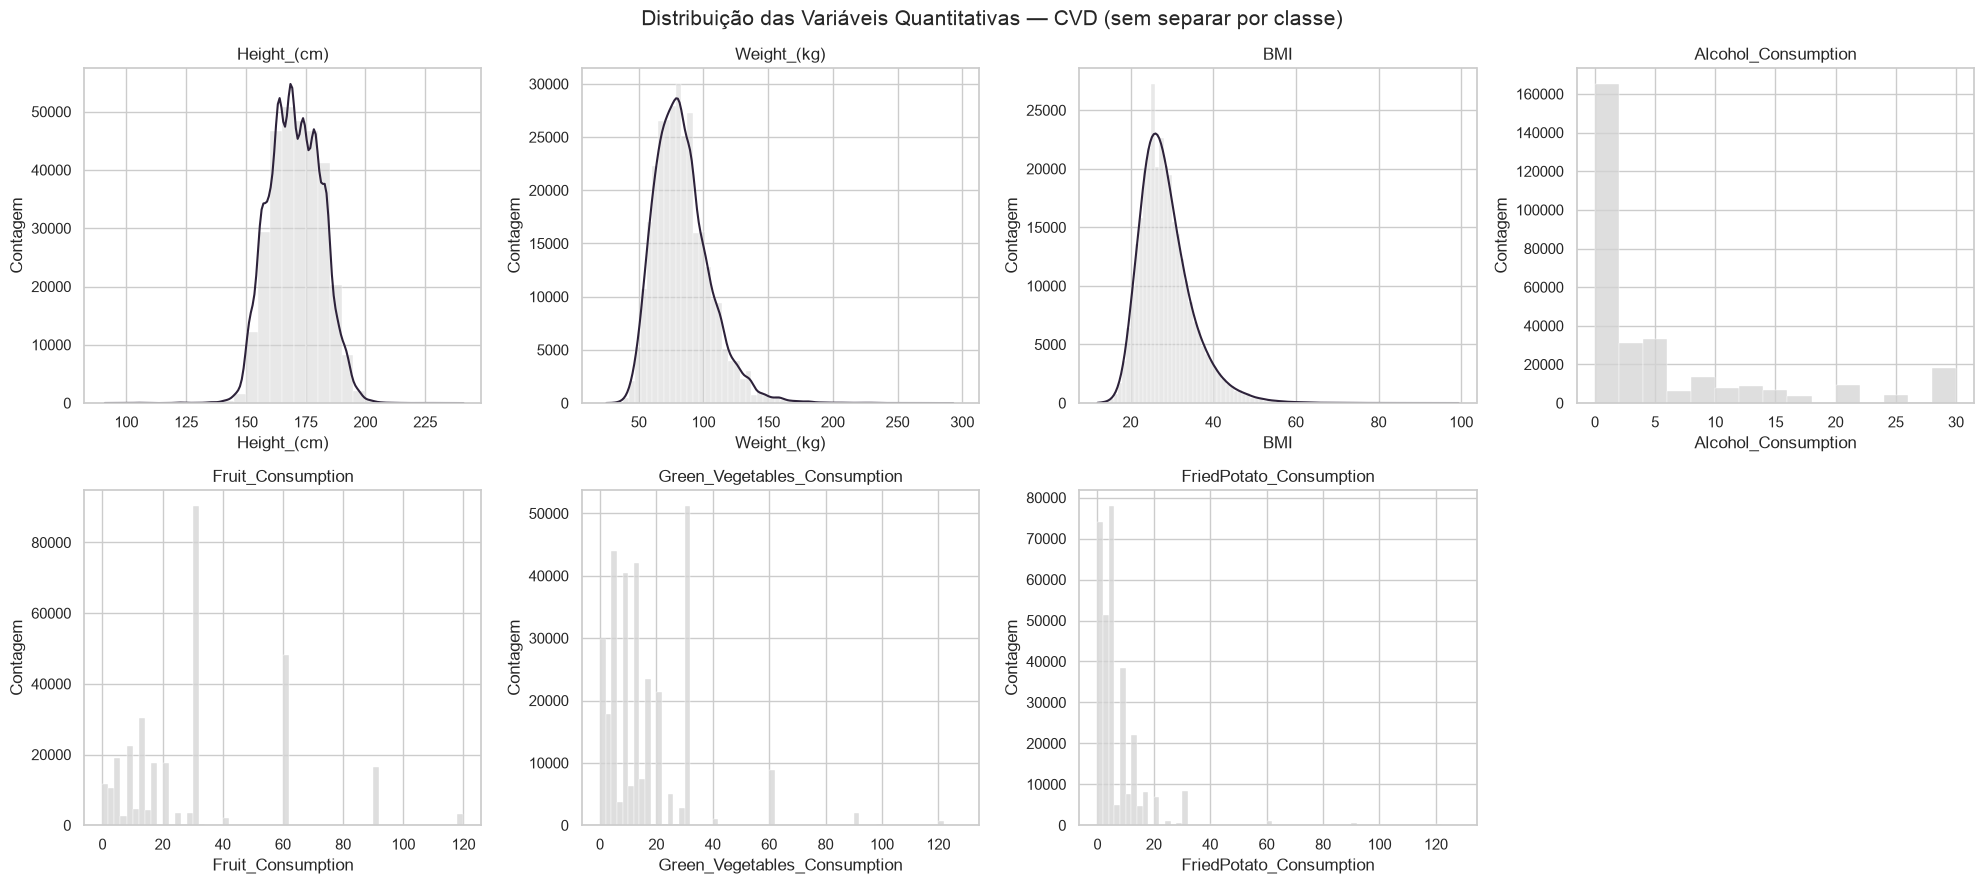

In [12]:
VARS_CONTINUAS = ["Height_(cm)", "Weight_(kg)", "BMI"]
# Altura e peso foram coletados em polegadas/libras e convertidos -> valores "em degraus".
# Bins mais largos (5 cm, ~10 lb) evitam o histograma serrilhado.
BINS_CONTINUAS = {"Height_(cm)": np.arange(90, 245, 5),
                  "Weight_(kg)": np.arange(20, 300, 4.5),
                  "BMI": np.arange(12, 100, 1)}

fig, axes = plt.subplots(2, 4, figsize=(20, 9))
axes = axes.ravel()

for i, col in enumerate(VARS_QUANT):
    usar_kde = col in VARS_CONTINUAS
    bins = BINS_CONTINUAS.get(col, np.arange(0, df[col].max() + 2, 2))
    sns.histplot(data=df, x=col, bins=bins, kde=usar_kde, kde_kws={"bw_adjust": 2},
                 color=COR_NEUTRA, edgecolor="white", linewidth=0.3, ax=axes[i])
    if usar_kde:
        axes[i].lines[0].set_color(COR_DESTAQUE)
    axes[i].set_title(col)
    axes[i].set_ylabel("Contagem")

for ax in axes[len(VARS_QUANT):]:
    ax.axis("off")

fig.suptitle("Distribuição das Variáveis Quantitativas — CVD (sem separar por classe)", fontsize=15)
plt.tight_layout()
plt.show()

**Como ler:** `Height_(cm)` tem formato de sino (altura e peso foram respondidos em polegadas/libras e convertidos, por isso os valores vêm "em degraus" e usamos bins mais largos); `Weight` e `BMI` têm cauda à direita. Nas variáveis de consumo aparecem **picos em valores "redondos"** (4, 8, 12, 30, 60...). Isso vem do questionário: a pessoa responde "1 vez por semana" ou "1 vez por dia" e o valor é convertido para vezes/mês. É um efeito de **arredondamento da autodeclaração (heaping)**, não um erro.

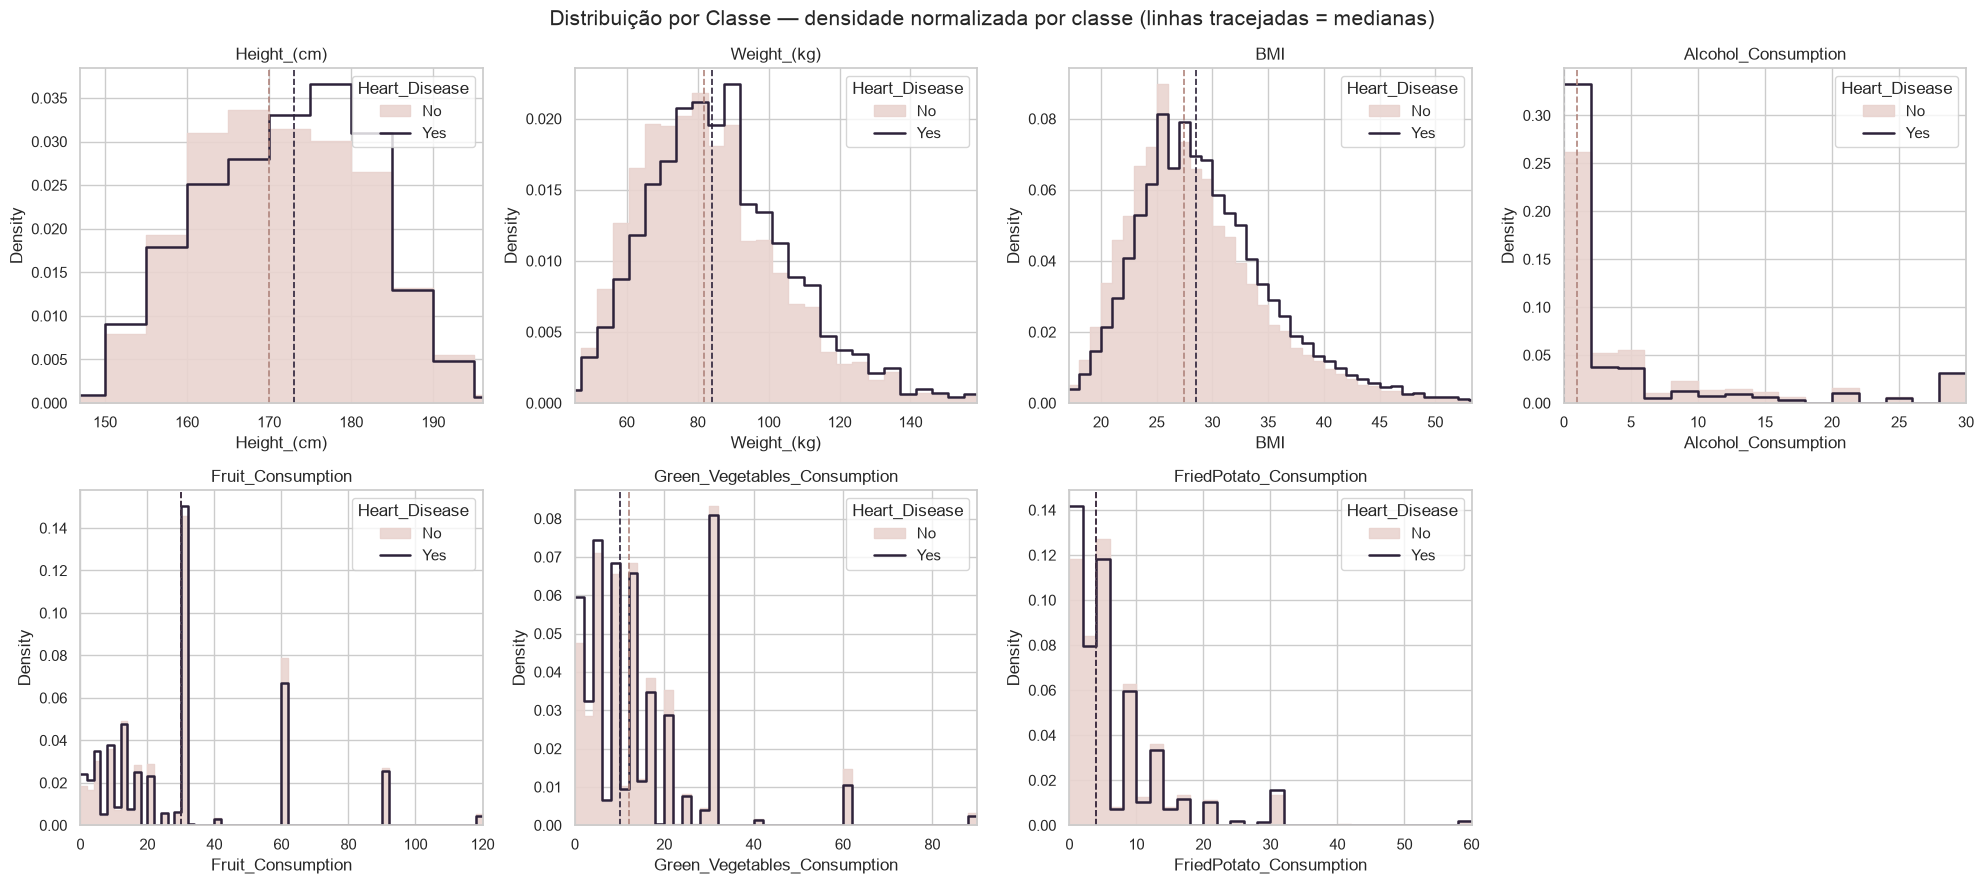

In [13]:
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
axes = axes.ravel()

for i, col in enumerate(VARS_QUANT):
    lim = (df[col].quantile(0.005), df[col].quantile(0.995))     # corta só as pontas extremas p/ visualizar
    continua = col in VARS_CONTINUAS
    bins = BINS_CONTINUAS[col] if continua else np.arange(lim[0], lim[1] + 2, 2)
    dados = df[df[col].between(*lim)]

    sns.histplot(data=dados[dados["Heart_Disease"] == "No"], x=col, bins=bins, stat="density",
                 color=COR_CONTEXTO, element="step", fill=True, alpha=0.9, label="No", ax=axes[i])
    sns.histplot(data=dados[dados["Heart_Disease"] == "Yes"], x=col, bins=bins, stat="density",
                 color=COR_DESTAQUE, element="step", fill=False, linewidth=1.8, label="Yes", ax=axes[i])

    for classe, cor in [("No", "#b0857d"), ("Yes", COR_DESTAQUE)]:
        axes[i].axvline(df.loc[df["Heart_Disease"] == classe, col].median(),
                        color=cor, linestyle="--", linewidth=1.2)
    axes[i].set_xlim(lim)
    axes[i].set_title(col)
    axes[i].legend(title="Heart_Disease")

axes[-1].axis("off")
fig.suptitle("Distribuição por Classe — densidade normalizada por classe (linhas tracejadas = medianas)",
             fontsize=15)
plt.tight_layout()
plt.show()

**Para discutir:** agora que as classes estão em painéis separados (mesma escala de eixo X em cada linha), fica mais fácil ver: alguma variável parece ter formato bem diferente entre "Normal" e "Cardíaco"?

#### Testes de Aderência

*Será se o colesterol segue uma distribuição normal?*

O **Shapiro-Wilk** como o teste de aderência mais usado pra normalidade, junto com o **QQ-Plot** como visualização de apoio. Vamos testar com `chol`.

Shapiro-Wilk (amostra n=5000) — BMI: estatística=0.9128, p-valor=6.337e-47
D'Agostino-Pearson (n=308,774) — BMI: estatística=87024.6, p-valor=0
Rejeita H0 (normalidade)? Sim (alpha = 0.05)


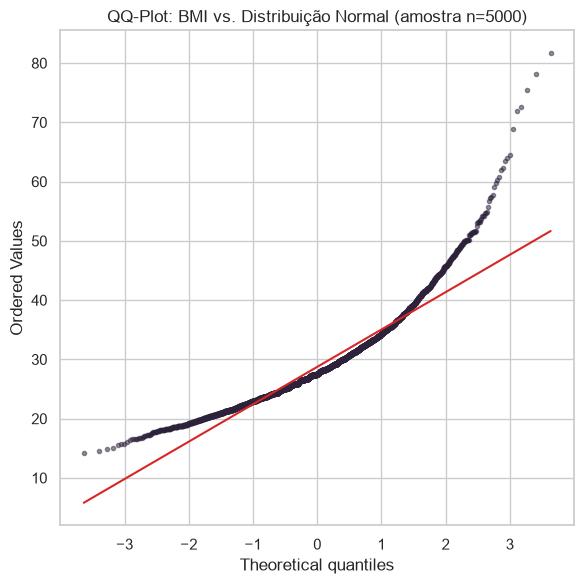

In [14]:
# CÉLULA 14 — Shapiro-Wilk + QQ-Plot do BMI (amostra de 5.000)
amostra_bmi = df["BMI"].sample(5000, random_state=SEED)

stat_sw, p_valor_sw = stats.shapiro(amostra_bmi)
stat_dp, p_valor_dp = stats.normaltest(df["BMI"])

print(f"Shapiro-Wilk (amostra n=5000) — BMI: estatística={stat_sw:.4f}, p-valor={p_valor_sw:.4g}")
print(f"D'Agostino-Pearson (n={len(df):,}) — BMI: estatística={stat_dp:.1f}, p-valor={p_valor_dp:.4g}")
print("Rejeita H0 (normalidade)?", "Sim" if p_valor_sw < 0.05 else "Não", "(alpha = 0.05)")

fig, ax = plt.subplots(figsize=(6, 6))
stats.probplot(amostra_bmi, dist="norm", plot=ax)
ax.get_lines()[0].set_markerfacecolor(COR_DESTAQUE)
ax.get_lines()[0].set_markeredgecolor(COR_DESTAQUE)
ax.get_lines()[0].set_markersize(3)
ax.get_lines()[0].set_alpha(0.5)
ax.get_lines()[1].set_color(COR_ALERTA)
ax.set_title("QQ-Plot: BMI vs. Distribuição Normal (amostra n=5000)")
plt.tight_layout()
plt.show()

**Como ler:** se os pontos (roxo) seguissem a reta vermelha de perto, a variável seguiria uma normal. Pontos que se afastam da reta nas pontas indicam cauda mais pesada ou mais leve que a normal — coerente com o resultado do Shapiro-Wilk acima.

**Nota: cuidado com duas armadilhas de interpretação**

- **Tamanho da amostra e poder do teste:** é comum achar que "poucos dados" tornam mais fácil rejeitar a normalidade e é o contrário. Amostras **pequenas** têm **menos poder estatístico**, ou seja, tendem a *não* rejeitar mesmo quando os dados realmente não são normais. Já amostras **muito grandes** (milhares de linhas) deixam o teste sensível demais, rejeitando por desvios triviais. Com n≈303 (nem pequeno, nem enorme) e três evidências concordando — skewness alto, QQ-Plot afastado da reta, e Shapiro-Wilk rejeitando — o resultado é razoavelmente confiável, não um artefato do tamanho da amostra.
- **Como afirmar o resultado:** quando o teste **rejeita** H0 (nosso caso, p < 0.05), a afirmação correta é "temos evidência estatística **contra** a normalidade" que é uma conclusão forte. A frase "não podemos garantir normalidade" cabe no caso oposto: quando o teste **não rejeita** H0, já que a ausência de rejeição nunca prova que os dados são normais, só que não há evidência suficiente contra.

In [15]:
amostra = df.sample(5000, random_state=SEED)

resultados_shapiro = []
for col in VARS_QUANT:
    stat, p = stats.shapiro(amostra[col])
    resultados_shapiro.append({"variavel": col, "estatistica_W": round(stat, 4),
                               "p_valor": p, "rejeita_normalidade": p < 0.05})

pd.DataFrame(resultados_shapiro).set_index("variavel").style.format({"p_valor": "{:.2e}"})

,estatistica_W,p_valor,rejeita_normalidade
variavel,,,
Height_(cm),0.982300,1.63e-24,True
Weight_(kg),0.951400,7.56e-38,True
BMI,0.912800,6.34e-47,True
Alcohol_Consumption,0.658200,3.86e-72,True
Fruit_Consumption,0.852700,6.00e-56,True
Green_Vegetables_Consumption,0.778000,1.42e-63,True
FriedPotato_Consumption,0.581200,2.31e-76,True


*Resposta*: **Todas** as variáveis rejeitam a normalidade, inclusive `Height_(cm)` (estatística W mais próxima de 1, ou seja, é a "menos não-normal": quase simétrica, mas com valores discretos em cm inteiros). As de consumo têm W bem mais baixos, coerente com as caudas longas e os picos de arredondamento. Conclusão: nas seções de comparação de grupos e correlação vamos priorizar **Spearman, Mann-Whitney e Kruskal-Wallis**.

**ECDF — outra forma de ver a distribuição**

Diferente do histograma, a ECDF não depende de escolher o número de bins: para cada valor no eixo X, a curva mostra a **proporção acumulada** de observações menores ou iguais àquele valor. Cada classe é normalizada separadamente, então o desbalanceamento não atrapalha.

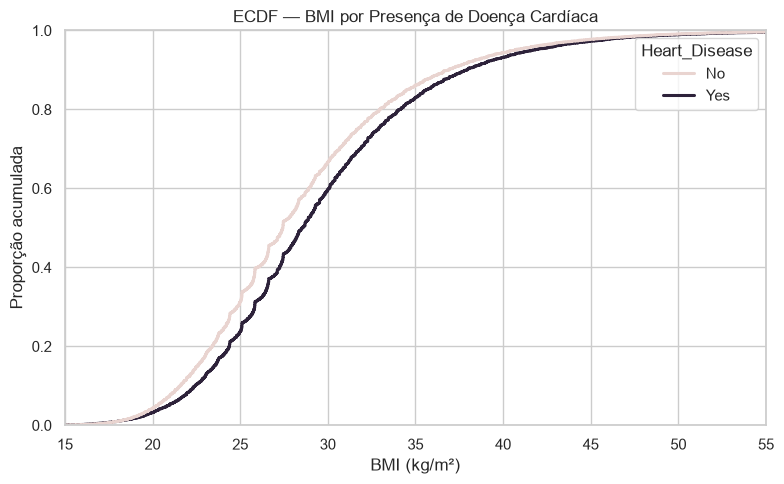

In [16]:
plt.figure(figsize=(8, 5))
sns.ecdfplot(data=df, x="BMI", hue="Heart_Disease", palette=PALETA_CLASSE, linewidth=2.2)
plt.xlim(15, 55)
plt.title("ECDF — BMI por Presença de Doença Cardíaca")
plt.xlabel("BMI (kg/m²)")
plt.ylabel("Proporção acumulada")
plt.tight_layout()
plt.show()

**Como ler:** a curva roxa (`Yes`) fica **à direita** da rosa (`No`) em praticamente toda a faixa, ou seja, para qualquer valor de BMI, uma fração menor dos cardíacos está abaixo dele. A maior distância entre as curvas está na faixa de **BMI ≈ 25–32** (sobrepeso/obesidade grau I). A diferença existe, mas é pequena.

### Métricas de Tendêncial Central

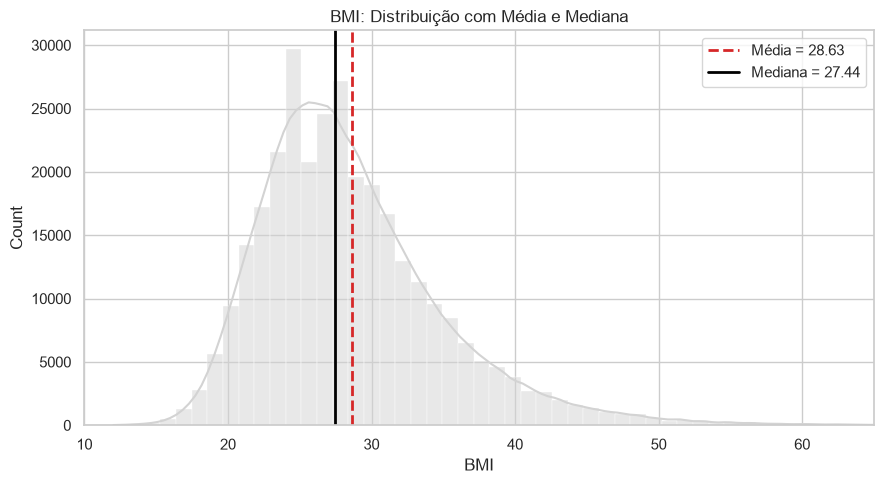

Média=28.63 | Mediana=27.44 | Moda=26.63


In [17]:
media_bmi = df["BMI"].mean()
mediana_bmi = df["BMI"].median()
moda_bmi = df["BMI"].mode()[0]

plt.figure(figsize=(9, 5))
sns.histplot(data=df, x="BMI", bins=80, kde=True, color=COR_NEUTRA, edgecolor="white", linewidth=0.3)
plt.axvline(media_bmi, color=COR_ALERTA, linestyle="--", linewidth=2, label=f"Média = {media_bmi:.2f}")
plt.axvline(mediana_bmi, color="black", linestyle="-", linewidth=2, label=f"Mediana = {mediana_bmi:.2f}")
plt.xlim(10, 65)
plt.title("BMI: Distribuição com Média e Mediana")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Média={media_bmi:.2f} | Mediana={mediana_bmi:.2f} | Moda={moda_bmi:.2f}")

### Dispersão

In [18]:
dispersao = df[VARS_QUANT].agg(["var", "std"]).T
dispersao["IQR"] = df[VARS_QUANT].quantile(0.75) - df[VARS_QUANT].quantile(0.25)
dispersao["CV_%"] = (df[VARS_QUANT].std() / df[VARS_QUANT].mean() * 100)
dispersao.round(2)

,var,std,IQR,CV_%
Height_(cm),113.60,10.66,15.00,6.25
Weight_(kg),455.59,21.34,27.21,25.53
BMI,42.55,6.52,7.64,22.79
Alcohol_Consumption,67.25,8.20,6.00,160.87
Fruit_Consumption,618.91,24.88,18.00,83.39
Green_Vegetables_Consumption,222.81,14.93,16.00,98.79
FriedPotato_Consumption,73.68,8.58,6.00,136.31


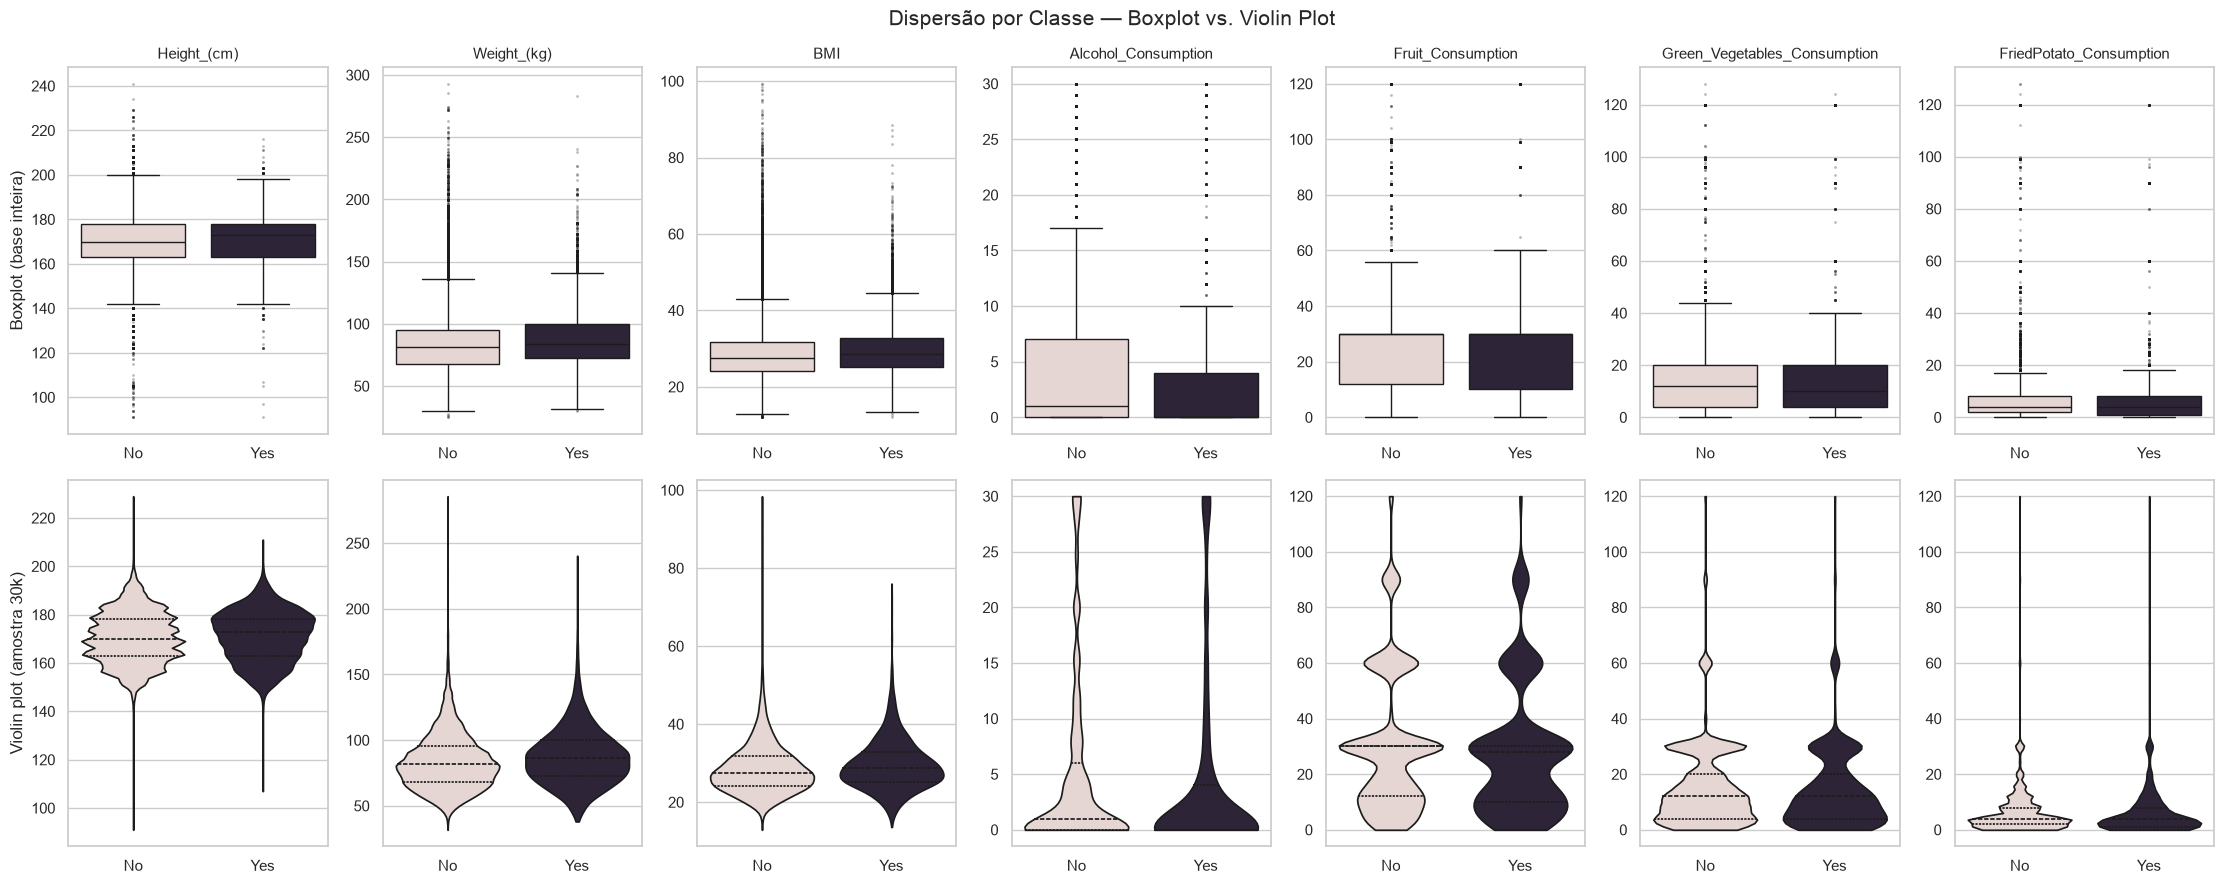

In [19]:
amostra_violin = df.sample(30000, random_state=SEED)
ordem = ["No", "Yes"]

fig, axes = plt.subplots(2, len(VARS_QUANT), figsize=(3.2 * len(VARS_QUANT), 9))

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, x="Heart_Disease", y=col, hue="Heart_Disease", order=ordem,
                palette=PALETA_CLASSE, legend=False, fliersize=1,
                flierprops=dict(alpha=0.3), ax=axes[0, i])
    axes[0, i].set_title(col, fontsize=11)
    axes[0, i].set_xlabel("")
    axes[0, i].set_ylabel("")

    sns.violinplot(data=amostra_violin, x="Heart_Disease", y=col, hue="Heart_Disease", order=ordem,
                   palette=PALETA_CLASSE, legend=False, cut=0, inner="quartile", ax=axes[1, i])
    axes[1, i].set_xlabel("")
    axes[1, i].set_ylabel("")

axes[0, 0].set_ylabel("Boxplot (base inteira)")
axes[1, 0].set_ylabel("Violin plot (amostra 30k)")
fig.suptitle("Dispersão por Classe — Boxplot vs. Violin Plot", fontsize=15)
plt.tight_layout()
plt.show()

**Pra discutir:** alguma variável mostra uma caixa (IQR) nitidamente mais alta ou mais baixa entre "Normal" e "Cardíaco"? Isso já é um indício — antes mesmo da análise bivariada formal — de que essa variável pode ajudar a diferenciar as duas classes.

## 4. Tratamento de Dados Ausentes e Outliers

Já vimos o retrato "antes". Não há ausentes para tratar, então o foco desta seção é **classificar e tratar os outliers**. Depois, rodamos a descritiva de novo ("depois") pra confirmar o efeito das escolhas.

### Detecção de Outliers por IQR

A regra clássica marca como outlier qualquer ponto fora de `[Q1 - 1.5*IQR, Q3 + 1.5*IQR]`.

In [20]:
def limites_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

resumo_outliers = {}
for col in VARS_QUANT:
    lim_inf, lim_sup = limites_iqr(df[col])
    n_outliers = ((df[col] < lim_inf) | (df[col] > lim_sup)).sum()
    resumo_outliers[col] = {
        "limite_inferior": round(lim_inf, 2),
        "limite_superior": round(lim_sup, 2),
        "min_observado": df[col].min(),
        "max_observado": df[col].max(),
        "n_outliers": n_outliers,
        "%_outliers": round(n_outliers / len(df) * 100, 2),
    }

pd.DataFrame(resumo_outliers).T

,limite_inferior,limite_superior,min_observado,max_observado,n_outliers,%_outliers
Height_(cm),140.50,200.50,91.00,241.00,1055.0,0.34
Weight_(kg),27.23,136.06,24.95,293.02,7326.0,2.37
BMI,12.75,43.31,12.02,99.33,9530.0,3.09
Alcohol_Consumption,-9.00,15.00,0.00,30.00,36147.0,11.71
Fruit_Consumption,-15.00,57.00,0.00,120.00,68212.0,22.09
Green_Vegetables_Consumption,-20.00,44.00,0.00,128.00,11877.0,3.85
FriedPotato_Consumption,-7.00,17.00,0.00,128.00,19456.0,6.30


### Visualizando os Outliers

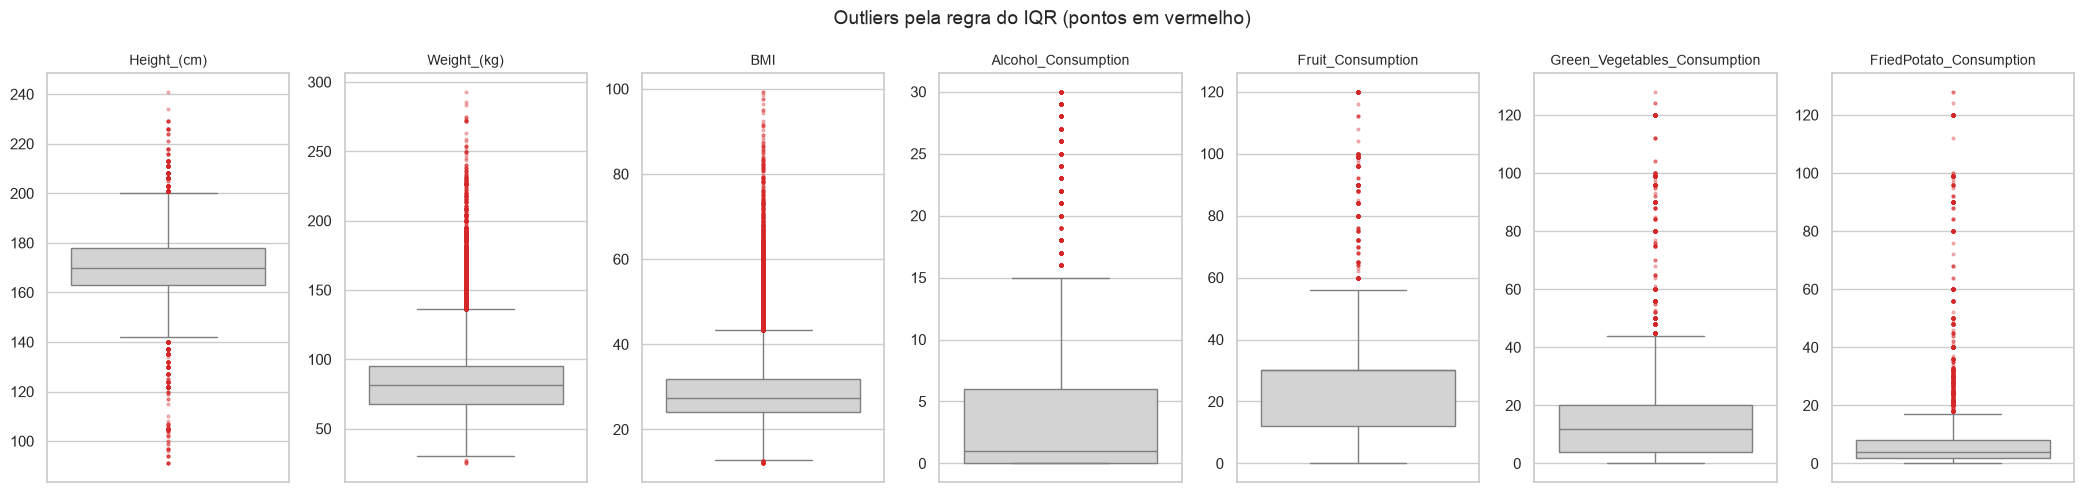

In [21]:
fig, axes = plt.subplots(1, len(VARS_QUANT), figsize=(3 * len(VARS_QUANT), 5))

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, y=col, color=COR_NEUTRA, fliersize=2,
                flierprops=dict(markerfacecolor=COR_ALERTA, markeredgecolor=COR_ALERTA,
                                marker="o", alpha=0.3),
                ax=axes[i])
    axes[i].set_title(col, fontsize=10)
    axes[i].set_ylabel("")

fig.suptitle("Outliers pela regra do IQR (pontos em vermelho)", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** os outliers encontrados parecem fisiologicamente plausíveis, ou parecem violar algum limite físico conhecido?

| Tipo | Cenário | O que fazer? |
|---|---|---|
| Estatístico | Legítimo | Manter / Transformar |
| De domínio | Viola regra de negócio ou condições físicas | Investigar! |
| Erros de dados | Falhas | Corrigir se possível / Remover como última opção |

Vamos investigar os extremos de altura e BMI com conhecimento de domínio, e checar se o BMI é coerente com peso/altura:

In [22]:
# 1) O BMI informado bate com peso / altura²?
bmi_calculado = df["Weight_(kg)"] / (df["Height_(cm)"] / 100) ** 2
diferenca = (bmi_calculado - df["BMI"]).abs()
print(f"Maior diferença entre BMI informado e calculado: {diferenca.max():.2f}")
print(f"Linhas com diferença > 1 ponto de BMI: {(diferenca > 1).sum()}\n")

# 2) Valores fisicamente implausíveis (regras de domínio)
regras_dominio = {
    "Altura < 120 cm (adulto)": df["Height_(cm)"] < 120,
    "Altura > 220 cm": df["Height_(cm)"] > 220,
    "BMI < 13 (desnutrição extrema)": df["BMI"] < 13,
    "BMI > 80": df["BMI"] > 80,
    "Batata frita > 90x/mês (3x/dia)": df["FriedPotato_Consumption"] > 90,
}
pd.DataFrame({"n_linhas": {k: v.sum() for k, v in regras_dominio.items()}})

Maior diferença entre BMI informado e calculado: 0.99
Linhas com diferença > 1 ponto de BMI: 0



,n_linhas
Altura < 120 cm (adulto),67
Altura > 220 cm,19
BMI < 13 (desnutrição extrema),33
BMI > 80,60
Batata frita > 90x/mês (3x/dia),268


### Decidindo o Tratamento dos Dados Ausentes

Não há dados ausentes na base, então **nenhuma imputação ou remoção por ausência é necessária**. (A limitação de que os ausentes podem ter sido removidos antes da publicação já foi registrada na Seção 2.)

### Decidindo o Tratamento dos Outliers

- **Outliers estatísticos** (consumo alto, peso/BMI altos mas possíveis) → **manter**. São informação real e podem ser justamente os casos de maior risco.
- **Outliers de domínio** (altura < 120 ou > 220 cm, BMI < 13 ou > 80) → muito provavelmente **erros de autodeclaração**. Como não temos como corrigi-los (não dá pra ligar de novo pro entrevistado) e são ~0,05% da base, vamos **removê-los**.
- **Batata frita > 90x/mês** (268 linhas): improvável, mas possível (alguém que come fritas em toda refeição). Fica como outlier estatístico e é **mantido**.

In [23]:
df_antes = df.copy()
linhas_antes = len(df)

mascara_implausivel = (
    (df["Height_(cm)"] < 120) | (df["Height_(cm)"] > 220) |
    (df["BMI"] < 13) | (df["BMI"] > 80)
)
df = df[~mascara_implausivel].reset_index(drop=True)
linhas_depois = len(df)

print(f"Linhas antes: {linhas_antes:,} | Linhas depois: {linhas_depois:,} | "
      f"Removidas: {linhas_antes - linhas_depois} ({(linhas_antes - linhas_depois) / linhas_antes:.3%})")

Linhas antes: 308,774 | Linhas depois: 308,611 | Removidas: 163 (0.053%)


### Decidindo o Tratamento dos Outliers

Diferente dos ausentes, aqui **não vamos remover automaticamente**. Pelos valores encontrados (dentro de faixas clinicamente plausíveis, ainda que raras), a classificação mais provável é **"Estatístico"**, outliers legítimos, não erros de coleta. Sendo assim, o tratamento recomendado nesse caso é **manter** (a informação é real e pode ser clinicamente relevante — por exemplo, exatamente os pacientes com colesterol mais extremo podem ser os de maior risco) ou, se for necessário para alguma técnica estatística específica mais à frente (ex: métodos sensíveis à assimetria), **transformar**.

Vamos manter os valores originais por enquanto, mas ilustrar como ficaria uma transformação logarítmica em `FriedPotato_Consumption` — útil caso, mais adiante em análises futuras, a assimetria atrapalhe algum teste ou modelo.

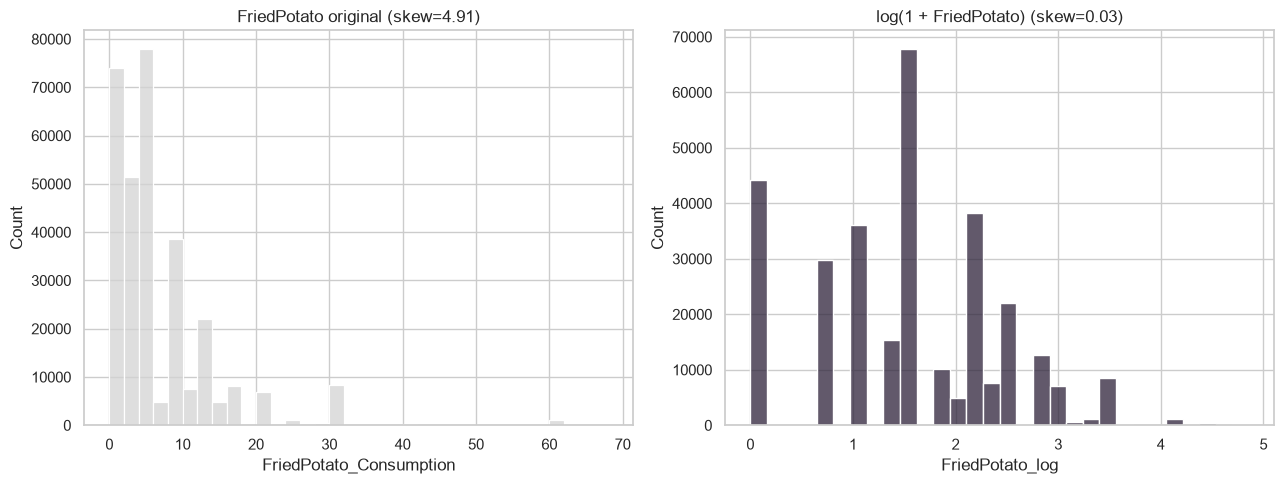

In [24]:
df["FriedPotato_log"] = np.log1p(df["FriedPotato_Consumption"])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.histplot(data=df, x="FriedPotato_Consumption", bins=np.arange(0, 70, 2),
             color=COR_NEUTRA, edgecolor="white", ax=axes[0])
axes[0].set_title(f"FriedPotato original (skew={df['FriedPotato_Consumption'].skew():.2f})")

sns.histplot(data=df, x="FriedPotato_log", bins=30, color=COR_DESTAQUE, edgecolor="white", ax=axes[1])
axes[1].set_title(f"log(1 + FriedPotato) (skew={df['FriedPotato_log'].skew():.2f})")

plt.tight_layout()
plt.show()

**Pra discutir:** a transformação logarítmica reduziu visivelmente a assimetria? Mantivemos `chol_log` só como demonstração, mas não vamos usá-la nas próximas seções. A ideia foi mostrar como opção se fosse o objetivo de, por exemplo, alimentar um teste paramétrico que exige normalidade.

**Nota para quando vocês replicarem no dataset de vocês:** nem todo outlier deve ser removido. Antes de decidir, classifiquem: é um valor estatisticamente raro mas plausível (manter/transformar), viola alguma regra física ou de negócio (investigar antes de decidir), ou é claramente um erro de digitação/coleta (corrigir ou remover)?

*Resposta*: Sim, e muito. A skewness cai de ~4,9 para perto de 0, e a cauda longa à direita desaparece. Mantemos `FriedPotato_log` só como demonstração; nas próximas seções usamos a variável original (os testes não-paramétricos não precisam da transformação, pois trabalham com postos/ranks).

## 5. Estatística Descritiva pt 2

Fechando o ciclo iterativo: tratamos os ausentes e decidimos manter os outliers. Agora rodamos a mesma bateria de estatísticas da Seção 3 para comparar diretamente com o "antes".

In [25]:
desc_depois = df[VARS_QUANT].describe().T
desc_depois["skewness"] = df[VARS_QUANT].skew()
desc_depois["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc_depois[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="Blues", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
Height_(cm),170.63,170.00,10.60,120.00,218.00,0.06,-0.36
Weight_(kg),83.58,81.65,21.26,24.95,283.50,1.02,2.24
BMI,28.61,27.44,6.46,13.00,79.71,1.26,3.07
Alcohol_Consumption,5.10,1.00,8.20,0.00,30.00,1.88,2.54
Fruit_Consumption,29.84,30.00,24.88,0.00,120.00,1.25,1.25
Green_Vegetables_Consumption,15.11,12.00,14.93,0.00,128.00,2.42,9.44
FriedPotato_Consumption,6.30,4.00,8.58,0.00,128.00,4.91,42.26


### Comparando "antes" x "depois""



In [26]:
comparacao = pd.DataFrame({
    "skewness_antes": desc["skewness"],
    "skewness_depois": desc_depois["skewness"],
    "kurtosis_antes": desc["kurtosis"],
    "kurtosis_depois": desc_depois["kurtosis"],
})
comparacao["delta_skewness"] = (comparacao["skewness_depois"] - comparacao["skewness_antes"]).round(3)
comparacao["delta_kurtosis"] = (comparacao["kurtosis_depois"] - comparacao["kurtosis_antes"]).round(3)
comparacao.round(3)

,skewness_antes,skewness_depois,kurtosis_antes,kurtosis_depois,delta_skewness,delta_kurtosis
Height_(cm),0.015,0.060,0.006,-0.357,0.045,-0.363
Weight_(kg),1.058,1.019,2.573,2.236,-0.039,-0.338
BMI,1.376,1.259,4.240,3.067,-0.118,-1.174
Alcohol_Consumption,1.885,1.885,2.539,2.537,-0.000,-0.002
Fruit_Consumption,1.248,1.248,1.253,1.253,-0.000,-0.000
Green_Vegetables_Consumption,2.416,2.415,9.445,9.442,-0.000,-0.003
FriedPotato_Consumption,4.912,4.913,42.223,42.258,0.002,0.036


**Pra discutir:** os valores mudaram muito? Fazia sentido esperar uma diferença grande, considerando que removemos só ~2% das linhas e decidimos **não** alterar nenhum outlier? Esse resultado (pouca mudança) é, na verdade, uma confirmação de que o tratamento foi conservador — não um sinal de que ele não fez nada de útil.

**Pra discutir:** os valores mudaram muito?

*Resposta*: Mudaram pouco na maioria, como esperado, já que removemos só 163 linhas (~0,05%). A mudança mais visível é na **curtose do `BMI`** (4,24 → 3,07), e um pouco no `Weight` e na `Height`, porque os casos removidos eram justamente os mais extremos das caudas: poucas linhas, mas muito "pesadas" para a curtose. As variáveis de consumo praticamente não mudam, porque decidimos não mexer nelas. Pouca mudança confirma que o tratamento foi **conservador**: limpou erros evidentes sem distorcer a distribuição real.

**O colesterol ainda rejeita normalidade?**

Vamos rodar o mesmo Shapiro-Wilk da Seção 3, agora nos dados tratados.

In [27]:
stat_sw_depois, p_valor_sw_depois = stats.shapiro(df["BMI"].sample(5000, random_state=SEED))
print(f"Shapiro-Wilk (antes)  — BMI: estatística={stat_sw:.4f}, p-valor={p_valor_sw:.4g}")
print(f"Shapiro-Wilk (depois) — BMI: estatística={stat_sw_depois:.4f}, p-valor={p_valor_sw_depois:.4g}")

Shapiro-Wilk (antes)  — BMI: estatística=0.9128, p-valor=6.337e-47
Shapiro-Wilk (depois) — BMI: estatística=0.9361, p-valor=5.821e-42


**Visualizando antes x depois, lado a lado**

Vamos sobrepor as distribuições de duas variáveis que mais chamaram atenção na Seção 4 (`chol` e `oldpeak`), comparando a versão original (`df_antes`) com a tratada (`df`).

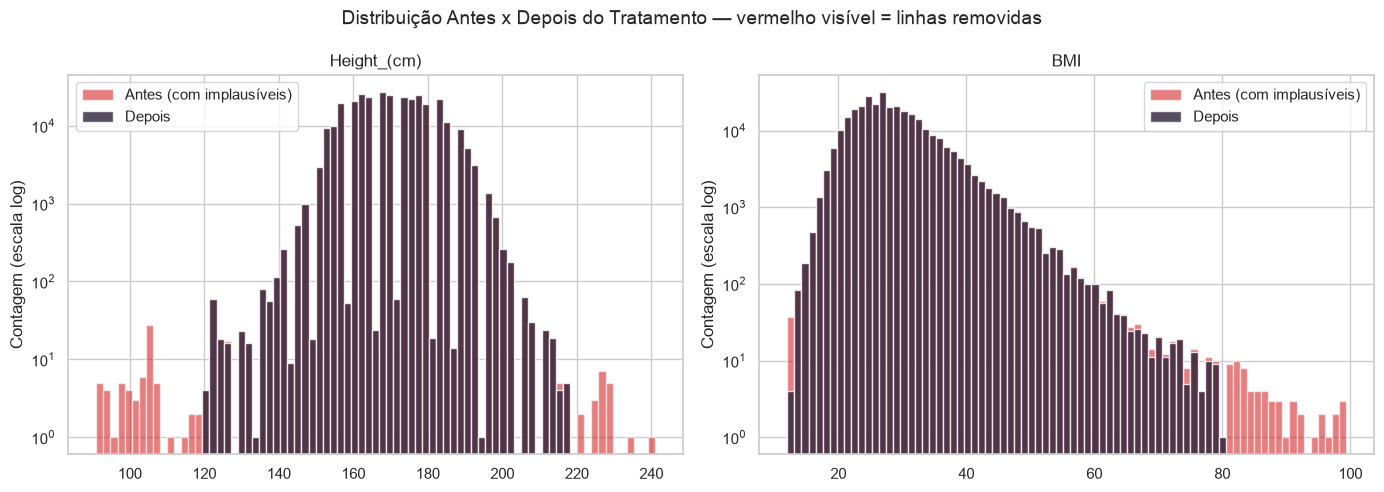

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, col in zip(axes, ["Height_(cm)", "BMI"]):
    bins = np.linspace(df_antes[col].min(), df_antes[col].max(), 80)
    ax.hist(df_antes[col], bins=bins, color=COR_ALERTA, alpha=0.6, label="Antes (com implausíveis)")
    ax.hist(df[col], bins=bins, color=COR_DESTAQUE, alpha=0.8, label="Depois")
    ax.set_yscale("log")
    ax.set_title(col)
    ax.set_ylabel("Contagem (escala log)")
    ax.legend()

fig.suptitle("Distribuição Antes x Depois do Tratamento — vermelho visível = linhas removidas", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** as curvas "antes" e "depois" praticamente se sobrepõem? Isso é o esperado aqui, já que removemos poucas linhas e não tocamos nos outliers.

Guardem essa observação: em datasets onde o volume de ausentes/outliers for maior, essa mesma comparação pode mostrar uma diferença bem mais visível e sempre que essa checagem "antes x depois" que confirma (ou não) que o tratamento teve o efeito esperado, em vez de assumir isso às cegas.

*Resposta*: No miolo da distribuição, **sobrepõem perfeitamente** (o vermelho fica escondido atrás do roxo). Só aparecem barras vermelhas nas **pontas extremas**, exatamente onde aplicamos as regras de domínio. Sem a escala log, essa diferença seria invisível, o que reforça que o tratamento foi pontual.

## 6. Princípio Relacional

### Análise de Variáveis Qualitativas

Agora focaremos na avaliação de frequência e desbalanceamento das variáveis qualitativas.




#### Frequências absolutas e relativas

In [29]:
ORDENS = {
    "General_Health": ["Poor", "Fair", "Good", "Very Good", "Excellent"],
    "Checkup": ["Within the past year", "Within the past 2 years", "Within the past 5 years",
                "5 or more years ago", "Never"],
    "Age_Category": ["18-24", "25-29", "30-34", "35-39", "40-44", "45-49", "50-54",
                     "55-59", "60-64", "65-69", "70-74", "75-79", "80+"],
    "Diabetes": ["No", "No, pre-diabetes or borderline diabetes",
                 "Yes, but female told only during pregnancy", "Yes"],
}

for col, ordem_cat in ORDENS.items():
    df[col] = pd.Categorical(df[col], categories=ordem_cat, ordered=True)

print("Categorias ordinais configuradas:", list(ORDENS))

Categorias ordinais configuradas: ['General_Health', 'Checkup', 'Age_Category', 'Diabetes']


In [30]:
for col in VARS_QUALI:
    freq_abs = df[col].value_counts(sort=False)
    freq_rel = df[col].value_counts(normalize=True, sort=False).round(3)
    print(f"\n--- {col} ---")
    print(pd.concat([freq_abs.rename("absoluta"), freq_rel.rename("relativa")], axis=1))


--- General_Health ---
                absoluta  relativa
General_Health                    
Poor               11303     0.037
Fair               35775     0.116
Good               95304     0.309
Very Good         110324     0.357
Excellent          55905     0.181

--- Checkup ---
                         absoluta  relativa
Checkup                                    
Within the past year       239173     0.775
Within the past 2 years     37192     0.121
Within the past 5 years     17430     0.056
5 or more years ago         13413     0.043
Never                        1403     0.005

--- Exercise ---
          absoluta  relativa
Exercise                    
No           69399     0.225
Yes         239212     0.775

--- Heart_Disease ---
               absoluta  relativa
Heart_Disease                    
No               283649     0.919
Yes               24962     0.081

--- Skin_Cancer ---
             absoluta  relativa
Skin_Cancer                    
No             278624     0.

#### Visualizando as frequências

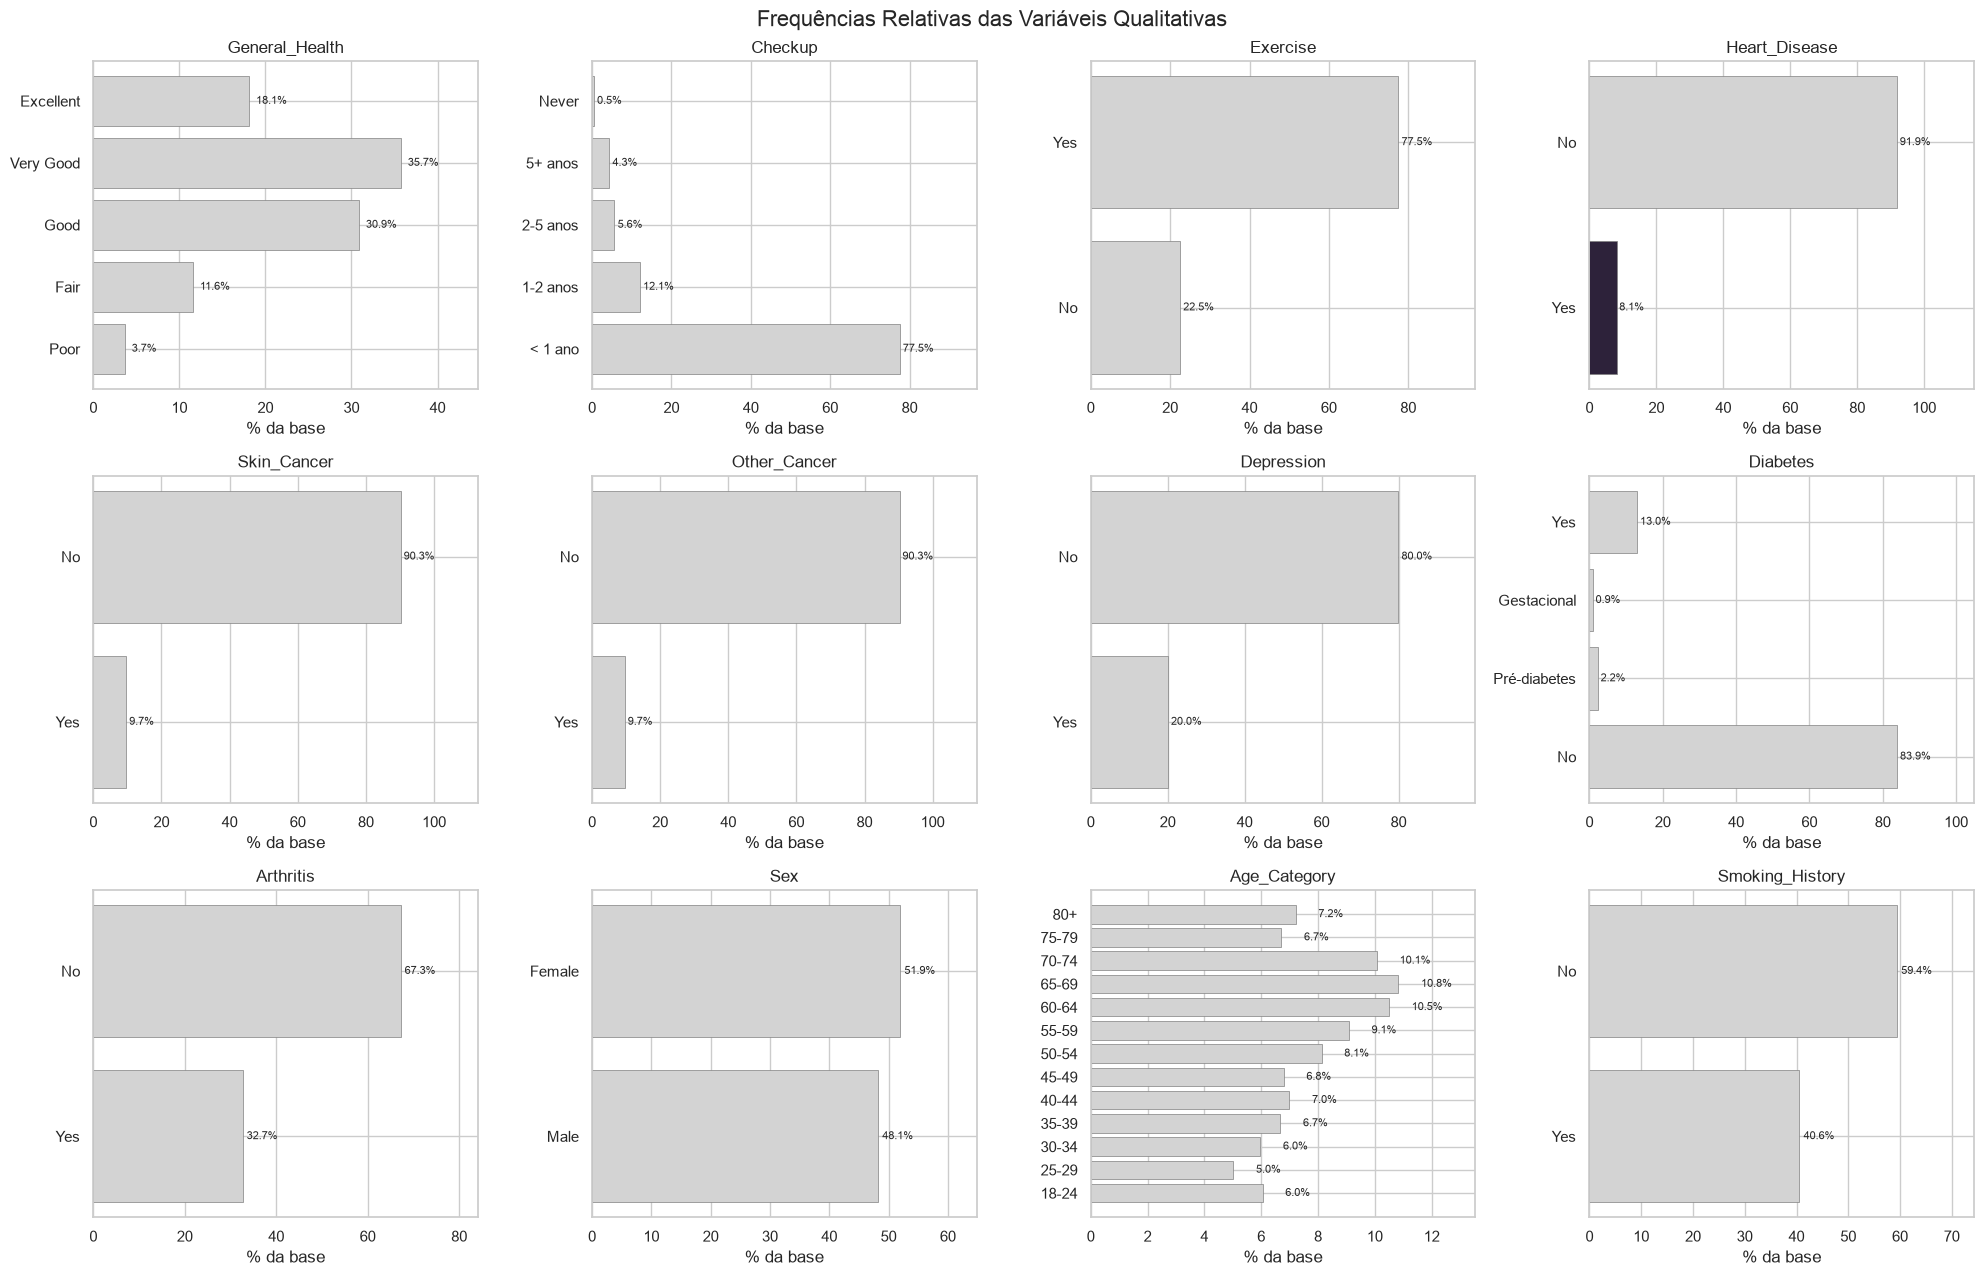

In [31]:
ROTULOS_CURTOS = {
    "No, pre-diabetes or borderline diabetes": "Pré-diabetes",
    "Yes, but female told only during pregnancy": "Gestacional",
    "Within the past year": "< 1 ano",
    "Within the past 2 years": "1-2 anos",
    "Within the past 5 years": "2-5 anos",
    "5 or more years ago": "5+ anos",
}

fig, axes = plt.subplots(3, 4, figsize=(20, 13))
axes = axes.ravel()

for i, col in enumerate(VARS_QUALI):
    freq = df[col].value_counts(normalize=True, sort=False) * 100
    if col not in ORDENS:
        freq = freq.sort_values()
    rotulos = [ROTULOS_CURTOS.get(str(c), str(c)) for c in freq.index]
    cores = [COR_DESTAQUE if col == "Heart_Disease" and c == "Yes" else COR_NEUTRA for c in freq.index]
    axes[i].barh(rotulos, freq.values, color=cores, edgecolor="gray", linewidth=0.5)
    for y, v in enumerate(freq.values):
        axes[i].text(v + 0.8, y, f"{v:.1f}%", va="center", fontsize=8)
    axes[i].set_title(col, fontsize=12)
    axes[i].set_xlim(0, freq.max() * 1.25)
    axes[i].set_xlabel("% da base")

fig.suptitle("Frequências Relativas das Variáveis Qualitativas", fontsize=16)
plt.tight_layout()
plt.show()

**Pra discutir:** alguma variável qualitativa está bem desbalanceada (uma categoria dominando quase todas as observações)? Isso pode impactar como vamos interpretar cruzamentos com essa variável mais na frente na análise bivariada.

*Resposta*: Sim, várias:
- **`Heart_Disease`**: só **8,1%** responderam "Yes". O próprio alvo é desbalanceado.
- **`Skin_Cancer`** e **`Other_Cancer`**: ~90% "No".
- **`Checkup`**: ~78% fizeram check-up no último ano; "Never" tem só 0,5%.
- **`Exercise`**: ~78% "Yes".
- **`Diabetes`**: as categorias "Pré-diabetes" e "Gestacional" juntas somam ~3%.

Já `Sex`, `Smoking_History` e `General_Health` são razoavelmente distribuídas. Em cruzamentos futuros, categorias muito pequenas (ex.: `Checkup = Never`) geram estimativas mais instáveis.

#### Desbalanceamento entre Classes

- **Razão de desbalanceamento** — # classe majoritária / # classe minoritária (quanto maior, mais desbalanceado).
- **Entropia de Shannon normalizada** — 1 = perfeitamente balanceado, 0 = uma classe domina tudo.

Vamos aplicar as duas em todas as qualitativas, incluindo o próprio alvo `doenca_cardiaca`.

In [32]:
from scipy.stats import entropy

def metrica_desbalanceamento(serie):
    contagens = serie.value_counts()
    contagens = contagens[contagens > 0]
    razao = contagens.max() / contagens.min()
    props = contagens / contagens.sum()
    n_classes = len(contagens)
    ent_normalizada = entropy(props, base=2) / np.log2(n_classes) if n_classes > 1 else np.nan
    return pd.Series({
        "n_classes": n_classes,
        "razao_desbalanceamento": round(razao, 2),
        "entropia_normalizada": round(ent_normalizada, 3),
    })

tabela_desb = pd.DataFrame({col: metrica_desbalanceamento(df[col]) for col in VARS_QUALI}).T
tabela_desb.sort_values("entropia_normalizada").style.format(
    {"n_classes": "{:.0f}", "razao_desbalanceamento": "{:.2f}", "entropia_normalizada": "{:.3f}"}
).background_gradient(cmap="magma", subset=["entropia_normalizada"])

,n_classes,razao_desbalanceamento,entropia_normalizada
Diabetes,4,97.97,0.388
Heart_Disease,2,11.36,0.405
Other_Cancer,2,9.33,0.459
Skin_Cancer,2,9.29,0.460
Checkup,5,170.47,0.482
Depression,2,3.99,0.723
Exercise,2,3.45,0.769
General_Health,5,9.76,0.877
Arthritis,2,2.06,0.912
Smoking_History,2,1.47,0.974


**Pra discutir:** alguma variável está com entropia bem próxima de 0 (bem desbalanceada)? E o próprio alvo `doenca_cardiaca` — está balanceado o suficiente pra não distorcer a análise bivariada e um eventual modelo mais à frente?

### Análise Bivariada

Agora começamos a avaliar como as variáveis se relacionam entre si e com o alvo `Heart_Disease`.

**Nota sobre amostras grandes:** com ~308 mil linhas, praticamente **qualquer** diferença vira "estatisticamente significativa" (p ≈ 0). Por isso, além do p-valor, vamos sempre olhar o **tamanho de efeito** (rank-biserial, Cramér's V), que diz se a diferença é *relevante*, não só *detectável*.

#### Quantitativa x Quantitativa - Correlação

* **Pearson** (linear, sensível a outliers, exige normalidade),
* **Spearman** e **Kendall** (relação monotônica, não exigem normalidade).

Como nenhuma variável passou no Shapiro-Wilk, Spearman é a escolha mais segura. O Kendall é calculado em uma amostra de 20.000 linhas, porque fica muito lento em 300 mil.

#### Quantitativa x Quantitativa - Correlação

Conhecemos três técnicas de correlação principais:
* **Pearson** (linear, sensível a outliers, exige normalidade),
* **Spearman** e **Kendall** (relação monotônica, não exigem normalidade).

Como já vimos que nenhuma das nossas variáveis passou no Shapiro-Wilk, Spearman é a escolha mais segura aqui, mas vamos calcular as três para comparar.

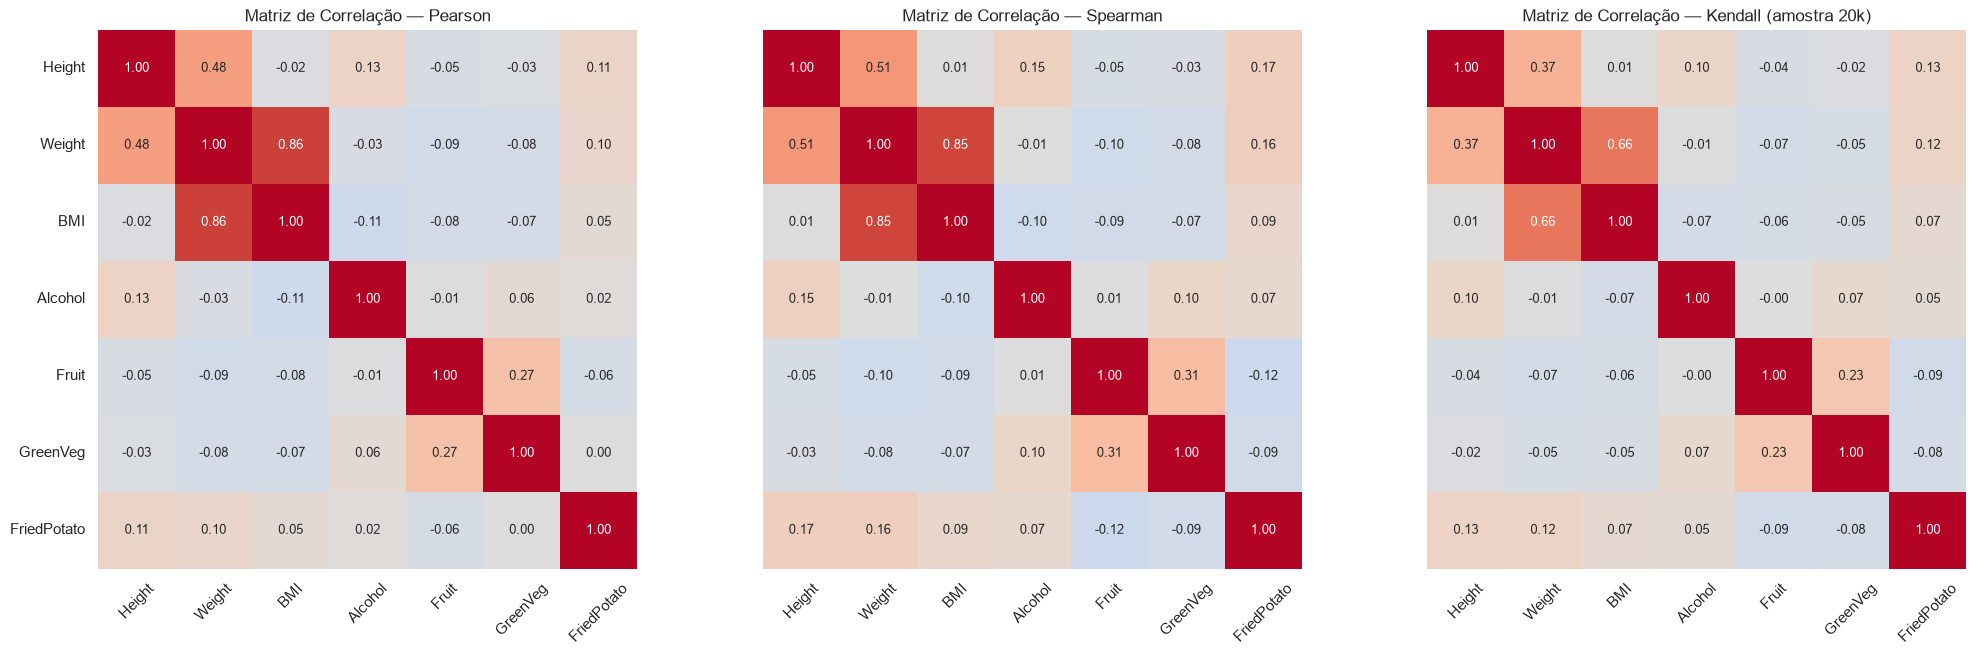

In [33]:
corr_pearson = df[VARS_QUANT].corr(method="pearson")
corr_spearman = df[VARS_QUANT].corr(method="spearman")
corr_kendall = df[VARS_QUANT].sample(20000, random_state=SEED).corr(method="kendall")

ROTULOS_CORR = ["Height", "Weight", "BMI", "Alcohol", "Fruit", "GreenVeg", "FriedPotato"]

fig, ax = plt.subplots(1, 3, figsize=(21, 6.5), sharey=True)
for a, (nome, matriz) in zip(ax, [("Pearson", corr_pearson), ("Spearman", corr_spearman),
                                   ("Kendall (amostra 20k)", corr_kendall)]):
    sns.heatmap(matriz, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True,
                xticklabels=ROTULOS_CORR, yticklabels=ROTULOS_CORR, cbar=False,
                annot_kws={"size": 9}, ax=a)
    a.set_title(f"Matriz de Correlação — {nome}")
    a.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

Como os dados do triângulo superior e inferior são simétricos, poderíamos plotar a matriz de correlação da seguinte forma.

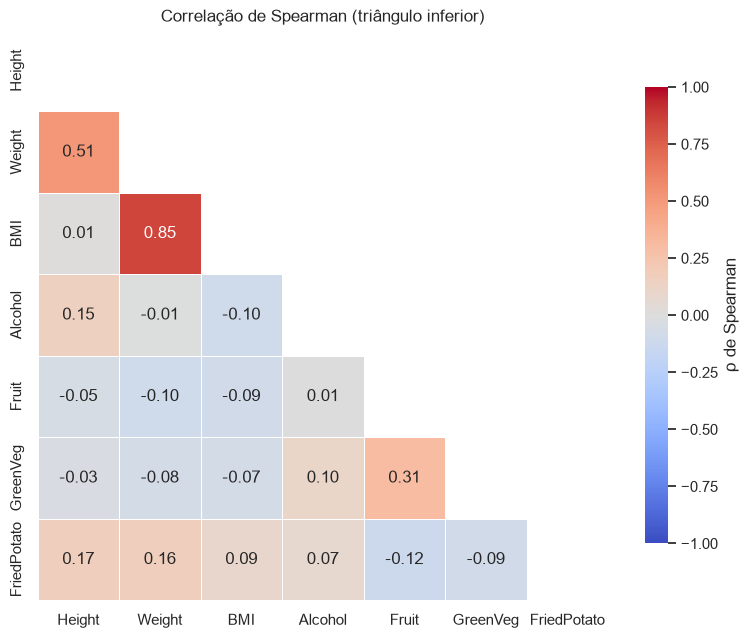

In [34]:
mask = np.triu(np.ones_like(corr_spearman, dtype=bool))

plt.figure(figsize=(8, 6.5))
sns.heatmap(corr_spearman, mask=mask, annot=True, cmap="coolwarm", fmt=".2f", square=True,
            vmin=-1, vmax=1, xticklabels=ROTULOS_CORR, yticklabels=ROTULOS_CORR,
            linewidths=0.5, cbar_kws={"shrink": 0.8, "label": "ρ de Spearman"})
plt.grid(False)
plt.title("Correlação de Spearman (triângulo inferior)")
plt.tight_layout()
plt.show()

**Pra discutir:** Pearson e Spearman divergem bastante em algum par?

*Resposta*: As correlações fortes são as esperadas por construção: **Weight × BMI (~0,86)** e **Height × Weight (~0,47–0,51)**, já que o BMI é calculado a partir de peso e altura. **Height × BMI ≈ 0**: o IMC foi desenhado justamente para "descontar" a altura. As variáveis de consumo correlacionam fracamente entre si, com exceção de **Fruit × GreenVeg** (ρ ≈ 0,31, moderada: quem come fruta tende a comer verdura).

Pearson e Spearman divergem um pouco nos pares com variáveis de consumo (ex.: `FriedPotato` com `Height`/`Weight`, Spearman maior). Isso é efeito das caudas longas e dos outliers, que afetam o Pearson. Kendall dá valores menores em módulo (é a escala dele), mas com o mesmo padrão de sinais.

#### Dispersão (scatter) entre duas variáveis quantitativas

Escolhemos `Height_(cm)` × `Weight_(kg)` por motivo de domínio: pessoas mais altas tendem a ser mais pesadas, e esse par é a base do cálculo do BMI. Usamos uma **amostra de 8.000 pontos**; com 300 mil, o gráfico vira um borrão. A classe `Yes` é desenhada por cima para não ficar escondida.

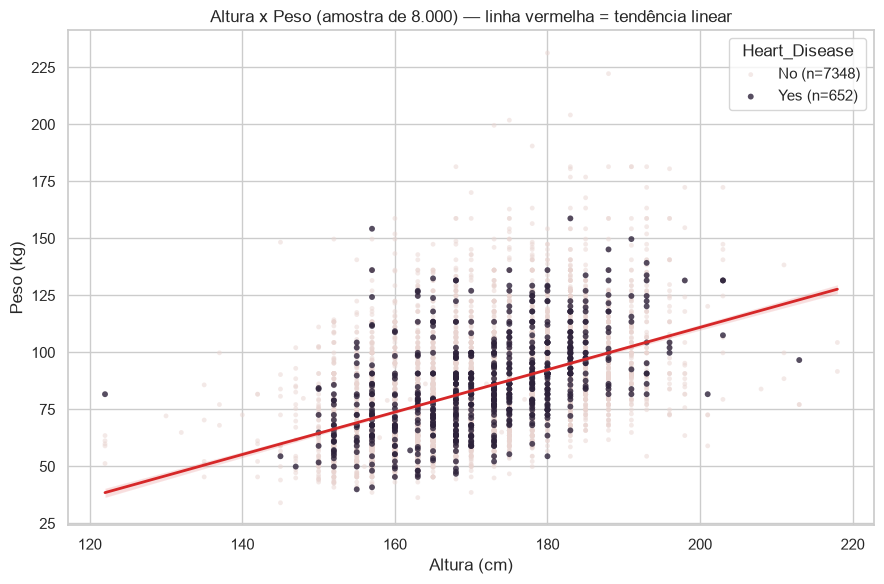

In [35]:
# CÉLULA 35 — Scatter Height x Weight por classe (amostra)
amostra_sc = df.sample(8000, random_state=SEED)

fig, ax = plt.subplots(figsize=(9, 6))
for classe, cor, alpha, tam in [("No", COR_CONTEXTO, 0.5, 12), ("Yes", COR_DESTAQUE, 0.8, 18)]:
    sub = amostra_sc[amostra_sc["Heart_Disease"] == classe]
    ax.scatter(sub["Height_(cm)"], sub["Weight_(kg)"], c=cor, alpha=alpha, s=tam,
               edgecolor="none", label=f"{classe} (n={len(sub)})")
sns.regplot(data=amostra_sc, x="Height_(cm)", y="Weight_(kg)", scatter=False,
            color=COR_ALERTA, line_kws={"linewidth": 2}, ax=ax)
ax.set_title("Altura x Peso (amostra de 8.000) — linha vermelha = tendência linear")
ax.set_xlabel("Altura (cm)")
ax.set_ylabel("Peso (kg)")
ax.legend(title="Heart_Disease")
plt.tight_layout()
plt.show()

**Pra discutir:** existe uma tendência visível? As classes ocupam regiões diferentes?

*Resposta*: Há uma **tendência positiva clara** (mais alto → mais pesado), mas com **muita dispersão vertical**: para uma mesma altura, o peso varia muito, e é essa variação que o BMI captura. Os pontos roxos (`Yes`) estão **espalhados por toda a nuvem**, misturados com os rosas. Altura e peso sozinhos não separam quem tem doença cardíaca.

#### Quantitativa x Qualitativa: Comparando Grupos

Como nenhuma variável é normal, o **Mann-Whitney U** é o principal (T-Test só como contraste). Como com n enorme tudo dá significativo, adicionamos o **tamanho de efeito rank-biserial** (r):
- |r| < 0,1 ~ desprezível, 0,1–0,3 ~ pequeno, 0,3–0,5 ~ médio, > 0,5 ~ grande.

In [36]:
# CÉLULA 36 — T-Test (Welch) x Mann-Whitney + tamanho de efeito
def classificar_efeito(r):
    r = abs(r)
    return "desprezível" if r < 0.1 else "pequeno" if r < 0.3 else "médio" if r < 0.5 else "grande"

resultados_comparacao = []
for col in VARS_QUANT:
    grupo_no = df.loc[df["Heart_Disease"] == "No", col]
    grupo_yes = df.loc[df["Heart_Disease"] == "Yes", col]

    stat_t, p_t = stats.ttest_ind(grupo_no, grupo_yes, equal_var=False)   # Welch (paramétrico)
    stat_u, p_u = stats.mannwhitneyu(grupo_yes, grupo_no)                  # não-paramétrico
    r_rb = 2 * stat_u / (len(grupo_yes) * len(grupo_no)) - 1               # rank-biserial (+ = Yes maior)

    resultados_comparacao.append({
        "variavel": col,
        "mediana_No": grupo_no.median(),
        "mediana_Yes": grupo_yes.median(),
        "p_valor_ttest": p_t,
        "p_valor_mannwhitney": p_u,
        "concordam": (p_t < 0.05) == (p_u < 0.05),
        "rank_biserial": round(r_rb, 3),
        "efeito": classificar_efeito(r_rb),
    })

(pd.DataFrame(resultados_comparacao).set_index("variavel")
   .style.format({"p_valor_ttest": "{:.2e}", "p_valor_mannwhitney": "{:.2e}", "mediana_No": "{:.2f}",
                  "mediana_Yes": "{:.2f}", "rank_biserial": "{:.3f}"}))

,mediana_No,mediana_Yes,p_valor_ttest,p_valor_mannwhitney,concordam,rank_biserial,efeito
variavel,,,,,,,
Height_(cm),170.00,173.00,8.07e-19,8.53e-31,True,0.044,desprezível
Weight_(kg),81.65,83.91,2.32e-140,2.48e-180,True,0.109,pequeno
BMI,27.44,28.55,7.19e-124,1.62e-172,True,0.107,pequeno
Alcohol_Consumption,1.00,0.00,1.01e-92,0.00e+00,True,-0.152,pequeno
Fruit_Consumption,30.00,30.00,1.36e-29,3.44e-37,True,-0.048,desprezível
Green_Vegetables_Consumption,12.00,10.00,1.80e-45,4.61e-52,True,-0.058,desprezível
FriedPotato_Consumption,4.00,4.00,2.02e-07,9.55e-40,True,-0.050,desprezível


**Pra discutir:** os dois testes concordam?

*Resposta*: Concordam em **todas**: tudo dá p ≈ 0, mas isso é efeito do n gigante. O **rank-biserial** conta a história real: só três variáveis chegam a efeito **pequeno**: `Alcohol_Consumption` (r ≈ −0,15, cardíacos bebem menos), `Weight` e `BMI` (r ≈ +0,11, cardíacos um pouco mais pesados). Altura e as variáveis de fruta/verdura/batata têm efeito **desprezível** (|r| < 0,06). Ou seja: há diferença estatística, mas nenhuma variável quantitativa, sozinha, diferencia bem os grupos.

**Nota:** o T-Test fica só como contraste pedagógico. O resultado a reportar é o Mann-Whitney com o tamanho de efeito.

*Exemplo com 3+ grupos — ANOVA x Kruskal-Wallis*

`General_Health` (saúde geral autoavaliada) tem 5 categorias ordenadas. Será que o BMI muda entre elas?

ANOVA          — BMI entre categorias de General_Health: F=5379.1, p-valor=0
Kruskal-Wallis — BMI entre categorias de General_Health: H=19359.0, p-valor=0
Tamanho de efeito (epsilon²) = 0.063


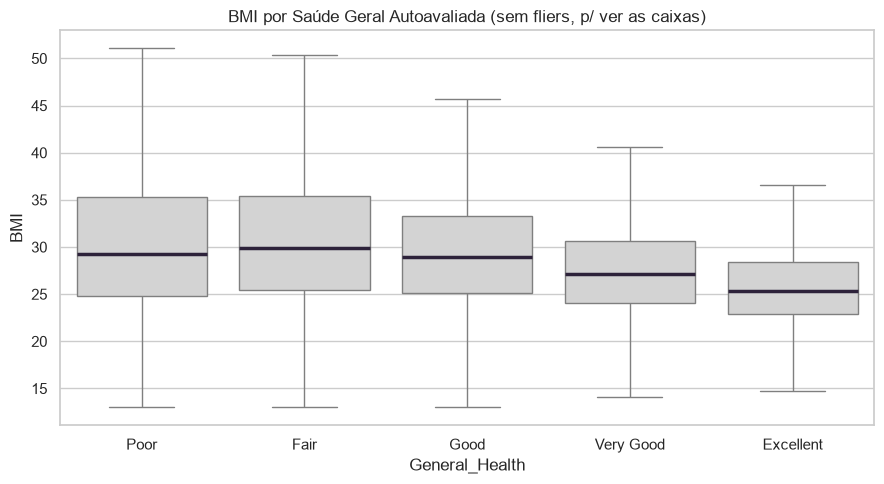

General_Health,Poor,Fair,Good,Very Good,Excellent
mediana_BMI,29.29,29.86,28.89,27.12,25.38


In [37]:
# CÉLULA 37 — ANOVA x Kruskal-Wallis: BMI entre categorias de General_Health
grupos_gh = [grupo["BMI"].values for _, grupo in df.groupby("General_Health", observed=True)]

stat_anova, p_anova = stats.f_oneway(*grupos_gh)   # paramétrico
stat_kw, p_kw = stats.kruskal(*grupos_gh)          # não-paramétrico
n_total = sum(len(g) for g in grupos_gh)
epsilon2 = stat_kw / (n_total - 1)                 # tamanho de efeito do Kruskal-Wallis

print(f"ANOVA          — BMI entre categorias de General_Health: F={stat_anova:.1f}, p-valor={p_anova:.3g}")
print(f"Kruskal-Wallis — BMI entre categorias de General_Health: H={stat_kw:.1f}, p-valor={p_kw:.3g}")
print(f"Tamanho de efeito (epsilon²) = {epsilon2:.3f}")

plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="General_Health", y="BMI", color=COR_NEUTRA, showfliers=False,
            medianprops=dict(color=COR_DESTAQUE, linewidth=2.5))
plt.title("BMI por Saúde Geral Autoavaliada (sem fliers, p/ ver as caixas)")
plt.xlabel("General_Health")
plt.tight_layout()
plt.show()

df.groupby("General_Health", observed=True)["BMI"].median().round(2).to_frame("mediana_BMI").T

**Pra discutir:** o Kruskal-Wallis concorda com a ANOVA?

*Resposta*: Sim, ambos rejeitam H0 com folga. Mais interessante do que o p-valor é o **padrão**: a mediana do BMI cai de "Fair" (29,9) até "Excellent" (25,4), ou seja, quem se avalia mais saudável tem IMC menor. A exceção é "Poor" (29,3), um pouco abaixo de "Fair": uma hipótese é que doenças graves também causam **perda de peso**, então o grupo mais doente mistura obesos e pessoas emagrecidas pela doença. O epsilon² (≈ 0,06) mostra efeito **pequeno**, mas coerente com o domínio. Reportamos o Kruskal-Wallis como principal.

#### Qualitativa x Qualitativa

Qui-Quadrado de independência entre `General_Health` e `Heart_Disease`, com **Cramér's V** como tamanho de efeito (0 = sem associação, 1 = associação perfeita). **Correção:** o heatmap de contagens fica dominado pela classe "No"; mostramos a **% de cardíacos em cada categoria** (normalizado por linha), que é o que realmente interessa.

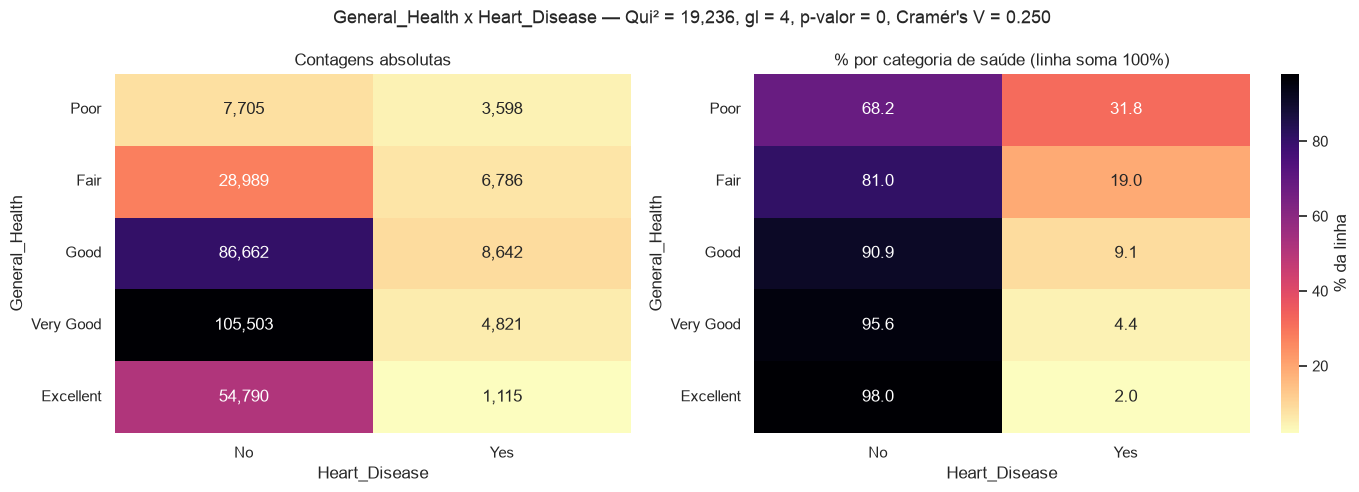

In [38]:
# CÉLULA 38 — Qui-Quadrado + Cramér's V: General_Health x Heart_Disease
def cramers_v(tabela):
    chi2 = stats.chi2_contingency(tabela)[0]
    n = tabela.to_numpy().sum()
    r, k = tabela.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1)))

contingencia_gh = pd.crosstab(df["General_Health"], df["Heart_Disease"])
chi2, p_chi2, gl, esperado = stats.chi2_contingency(contingencia_gh)
v_gh = cramers_v(contingencia_gh)
prop_gh = pd.crosstab(df["General_Health"], df["Heart_Disease"], normalize="index") * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1, 1.2]})
sns.heatmap(contingencia_gh, annot=True, fmt=",d", cmap="magma_r", cbar=False, ax=axes[0])
axes[0].set_title("Contagens absolutas")

sns.heatmap(prop_gh, annot=True, fmt=".1f", cmap="magma_r", cbar_kws={"label": "% da linha"}, ax=axes[1])
axes[1].set_title("% por categoria de saúde (linha soma 100%)")
for a in axes:
    a.tick_params(axis="y", rotation=0)

fig.suptitle(f"General_Health x Heart_Disease — Qui² = {chi2:,.0f}, gl = {gl}, "
             f"p-valor = {p_chi2:.3g}, Cramér's V = {v_gh:.3f}", fontsize=13)
plt.tight_layout()
plt.show()

**Pra discutir:** o p-valor indica independência ou associação?

*Resposta*: Há **associação estatisticamente significativa** (p ≈ 0), com **Cramér's V ≈ 0,25**, um efeito **moderado**, o maior entre todos os cruzamentos desta EDA. A tabela normalizada mostra um gradiente forte: **~32% de quem se avalia com saúde "Poor" tem doença cardíaca, contra ~2% de quem se avalia "Excellent"**. Atenção à direção causal: provavelmente é a doença que piora a autoavaliação de saúde (e não o contrário).

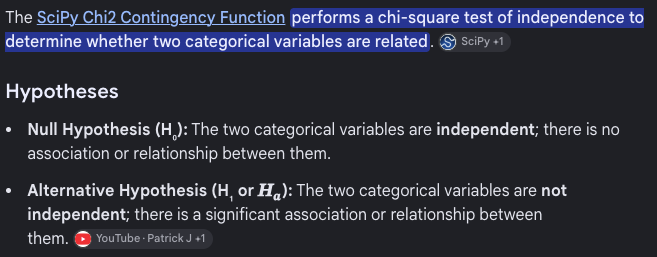

#### Avaliação de Fairness

Olhar o desbalanceamento da base inteira é só metade da história. Uma pergunta recorrente em discussões de **fairness** (justiça algorítmica) é: será que a distribuição do desfecho se comporta igual em diferentes subgrupos de atributos sensíveis (sexo e faixa etária, no nosso caso)? Se não, isso pode refletir um padrão real (ex: idade avançada é fator de risco documentado) ou um viés na forma como os dados foram coletados — de qualquer forma, é algo que vale mapear **antes** de qualquer modelagem.

In [39]:
# CÉLULA 39 — Criar rótulos de sexo e faixa etária agrupada + desbalanceamento
df["sexo_label"] = df["Sex"].map({"Female": "Feminino", "Male": "Masculino"})

mapa_faixa = {
    "18-24": "<45", "25-29": "<45", "30-34": "<45", "35-39": "<45", "40-44": "<45",
    "45-49": "45-54", "50-54": "45-54",
    "55-59": "55-64", "60-64": "55-64",
    "65-69": "65+", "70-74": "65+", "75-79": "65+", "80+": "65+",
}
df["faixa_etaria"] = pd.Categorical(df["Age_Category"].astype(str).map(mapa_faixa),
                                    categories=["<45", "45-54", "55-64", "65+"], ordered=True)

print("Desbalanceamento — sexo:")
print(metrica_desbalanceamento(df["sexo_label"]))
print("\nDesbalanceamento — faixa etária:")
print(metrica_desbalanceamento(df["faixa_etaria"]))

Desbalanceamento — sexo:
n_classes                 2.000
razao_desbalanceamento    1.080
entropia_normalizada      0.999
dtype: float64

Desbalanceamento — faixa etária:
n_classes                 4.000
razao_desbalanceamento    2.330
entropia_normalizada      0.962
dtype: float64


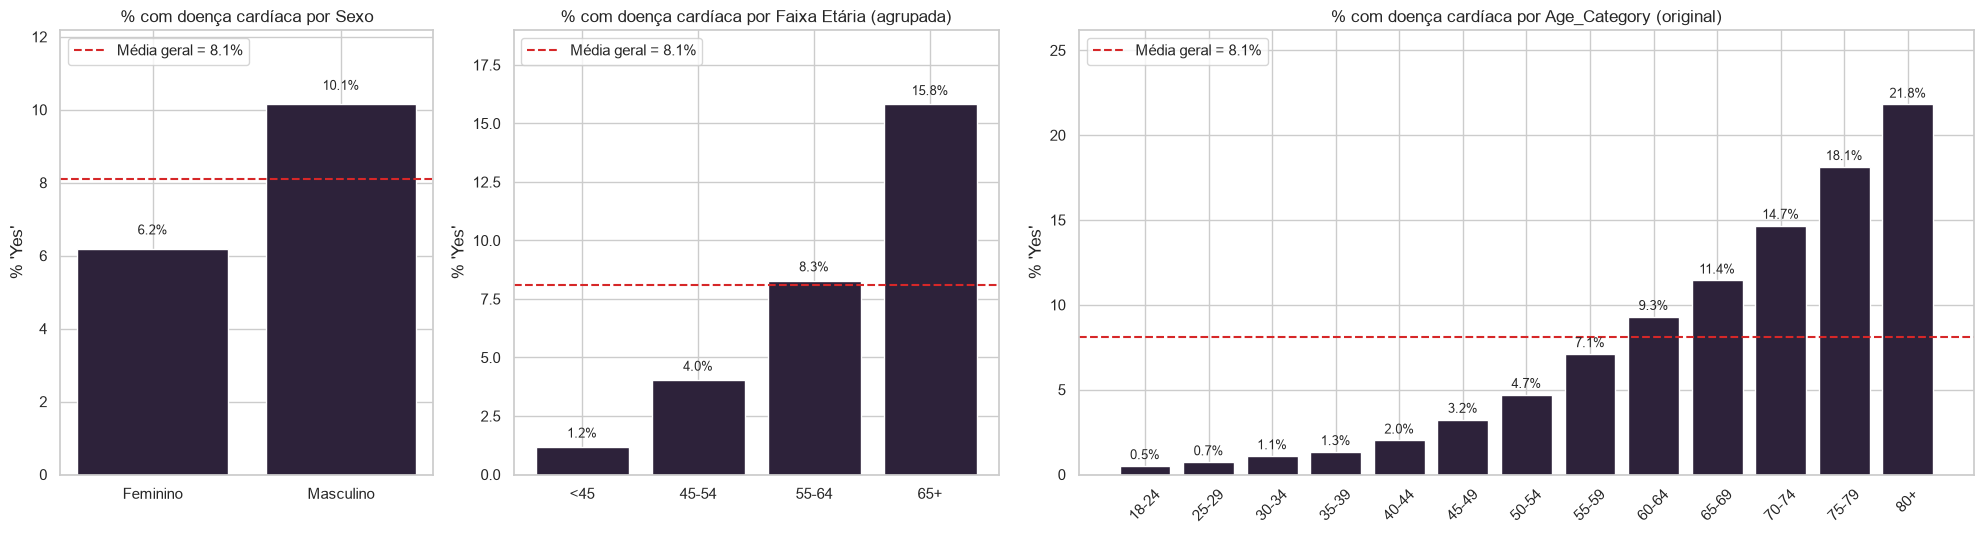

In [40]:
# CÉLULA 40 — Proporção de cardíacos por sexo e por faixa etária
prevalencia_geral = (df["Heart_Disease"] == "Yes").mean() * 100
prop_por_sexo = pd.crosstab(df["sexo_label"], df["Heart_Disease"], normalize="index") * 100
prop_por_faixa = pd.crosstab(df["faixa_etaria"], df["Heart_Disease"], normalize="index") * 100
prop_por_idade = pd.crosstab(df["Age_Category"], df["Heart_Disease"], normalize="index") * 100

fig, axes = plt.subplots(1, 3, figsize=(20, 5.5), gridspec_kw={"width_ratios": [1, 1.3, 2.4]})

for ax, prop, titulo in [(axes[0], prop_por_sexo, "por Sexo"),
                         (axes[1], prop_por_faixa, "por Faixa Etária (agrupada)"),
                         (axes[2], prop_por_idade, "por Age_Category (original)")]:
    valores = prop["Yes"]
    ax.bar(valores.index.astype(str), valores.values, color=COR_DESTAQUE)
    ax.axhline(prevalencia_geral, color=COR_ALERTA, linestyle="--", linewidth=1.5,
               label=f"Média geral = {prevalencia_geral:.1f}%")
    for x, v in enumerate(valores.values):
        ax.text(x, v + 0.4, f"{v:.1f}%", ha="center", fontsize=9)
    ax.set_title(f"% com doença cardíaca {titulo}")
    ax.set_ylabel("% 'Yes'")
    ax.set_ylim(0, valores.max() * 1.2)
    ax.tick_params(axis="x", rotation=0 if len(valores) < 6 else 45)
    ax.legend(loc="upper left")

plt.tight_layout()
plt.show()

**Pra discutir:** a proporção de diagnóstico positivo varia bastante entre sexo ou faixa etária?

*Resposta*:
- **Sexo:** homens relatam doença cardíaca em **~10,1%** dos casos, contra **~6,2%** das mulheres (razão ≈ 1,6×). Isso é coerente com a literatura (homens têm mais doença coronariana mais cedo), mas pode haver **viés de subdiagnóstico em mulheres**: os sintomas de infarto em mulheres costumam ser atípicos e historicamente menos investigados, e aqui a resposta depende de a pessoa *ter sido informada* por um médico.
- **Idade:** o gradiente é enorme e monotônico, de **0,5% (18–24) a ~22% (80+)**, ou seja, mais de 40× maior. É o fator de risco mais documentado da cardiologia.

Para um futuro modelo, isso significa que ele vai "aprender" idade e sexo como preditores fortes, e é preciso verificar se o desempenho (ex.: recall) é parecido entre homens e mulheres, para não reproduzir um possível subdiagnóstico feminino.

*Observação (corrigida em relação ao template):* o eixo Y não vai até 1 (100%), pois com prevalência de 8% as barras ficariam achatadas e as diferenças invisíveis; a linha tracejada mostra a média geral como referência.

sexo_label: Qui²=1,626.4, gl=1, p=0, Cramér's V=0.073
faixa_etaria: Qui²=15,724.5, gl=3, p=0, Cramér's V=0.226


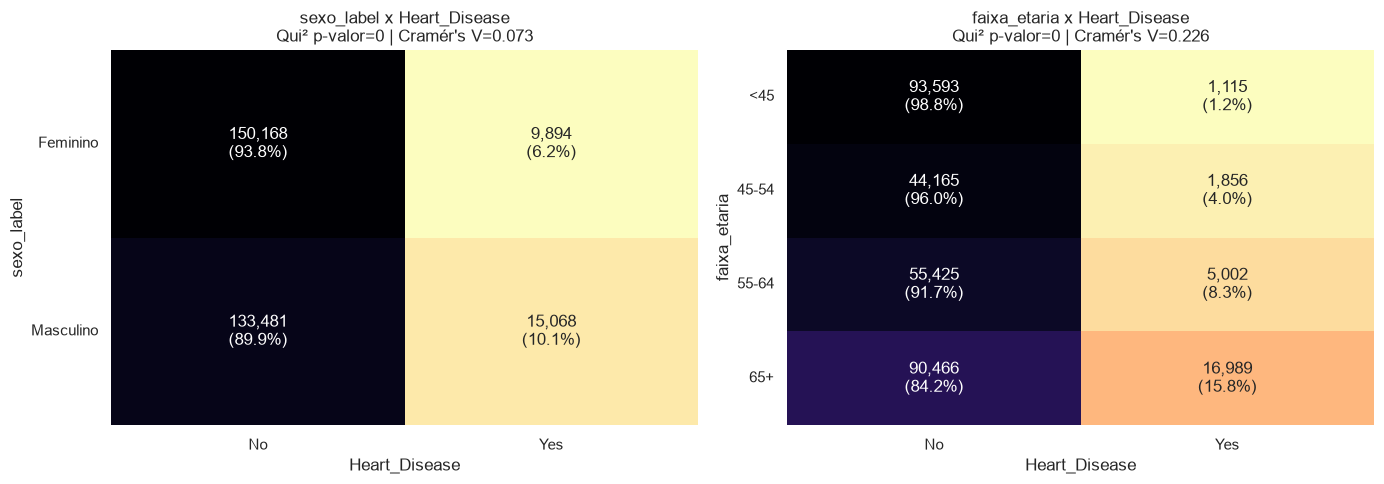

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, atributo in zip(axes, ["sexo_label", "faixa_etaria"]):
    contingencia = pd.crosstab(df[atributo], df["Heart_Disease"])
    chi2, p_valor, gl, esperado = stats.chi2_contingency(contingencia)
    v = cramers_v(contingencia)
    prop = pd.crosstab(df[atributo], df["Heart_Disease"], normalize="index") * 100

    rotulos = contingencia.map(lambda x: f"{x:,}") + "\n(" + prop.round(1).astype(str) + "%)"
    sns.heatmap(prop, annot=rotulos, fmt="", cmap="magma_r", cbar=False, ax=ax)
    ax.tick_params(axis="y", rotation=0)
    ax.set_title(f"{atributo} x Heart_Disease\nQui² p-valor={p_valor:.3g} | Cramér's V={v:.3f}")
    print(f"{atributo}: Qui²={chi2:,.1f}, gl={gl}, p={p_valor:.3g}, Cramér's V={v:.3f}")

plt.tight_layout()
plt.show()

**Pra discutir:** o Qui-Quadrado confirma associação?

*Resposta*: Sim, as duas associações são estatisticamente significativas (p ≈ 0). O Cramér's V mostra a diferença de força: **sexo tem efeito pequeno (V ≈ 0,07)** e **faixa etária tem efeito moderado (V ≈ 0,23)**, quase tão forte quanto `General_Health`. Lembrando: o teste aponta *que* existe associação, não *por quê*. A idade é um fator de risco biológico real; no sexo pode haver uma mistura de fator de risco real e viés de diagnóstico, e os dados sozinhos não permitem separar as duas coisas.

#### Outliers bivariados

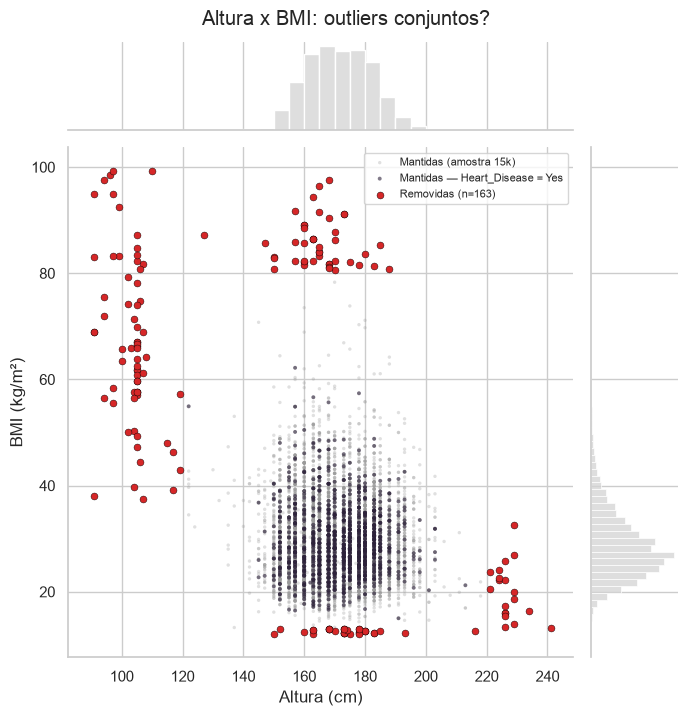

In [42]:
removidas = df_antes[mascara_implausivel]
amostra_bi = df_antes[~mascara_implausivel].sample(15000, random_state=SEED)

g = sns.JointGrid(data=amostra_bi, x="Height_(cm)", y="BMI", height=7)
g.ax_joint.scatter(amostra_bi["Height_(cm)"], amostra_bi["BMI"], s=6, alpha=0.3,
                   color="#9a9a9a", edgecolor="none", label="Mantidas (amostra 15k)")
yes = amostra_bi[amostra_bi["Heart_Disease"] == "Yes"]
g.ax_joint.scatter(yes["Height_(cm)"], yes["BMI"], s=8, alpha=0.6,
                   color=COR_DESTAQUE, edgecolor="none", label="Mantidas — Heart_Disease = Yes")
g.ax_joint.scatter(removidas["Height_(cm)"], removidas["BMI"], s=25, color=COR_ALERTA,
                   edgecolor="black", linewidth=0.3, label=f"Removidas (n={len(removidas)})")
sns.histplot(x=amostra_bi["Height_(cm)"], bins=np.arange(90, 245, 5), color=COR_NEUTRA, ax=g.ax_marg_x)
sns.histplot(y=amostra_bi["BMI"], bins=50, color=COR_NEUTRA, ax=g.ax_marg_y)
g.ax_joint.legend(loc="upper right", fontsize=8)
g.set_axis_labels("Altura (cm)", "BMI (kg/m²)")
g.figure.suptitle("Altura x BMI: outliers conjuntos?", y=1.02)
plt.show()

**Pra discutir:** existe algum ponto que não parecia outlier nos histogramas univariados, mas que se destaca na combinação?

*Resposta*: Sim. Os pontos vermelhos formam **quatro grupos**: (1) à esquerda, altura < 120 cm com BMI alto (em geral > 40): uma pessoa de ~1 metro com peso de adulto comum gera um IMC absurdo, padrão típico de **erro de unidade na altura**; (2) no topo, altura normal (150–190 cm) com BMI > 80, ou seja, peso declarado acima de 200 kg, provável erro no peso; (3) embaixo, BMI < 13 com altura normal, peso baixíssimo para a altura; (4) à direita, altura > 220 cm com BMI normal. Os grupos (2) e (3) nem pareciam tão estranhos olhando só a altura: é a **combinação** que os denuncia. A visão conjunta reforça que a remoção da Seção 4 fez sentido.

#### Análise Multivariada

##### Matriz de Correlação

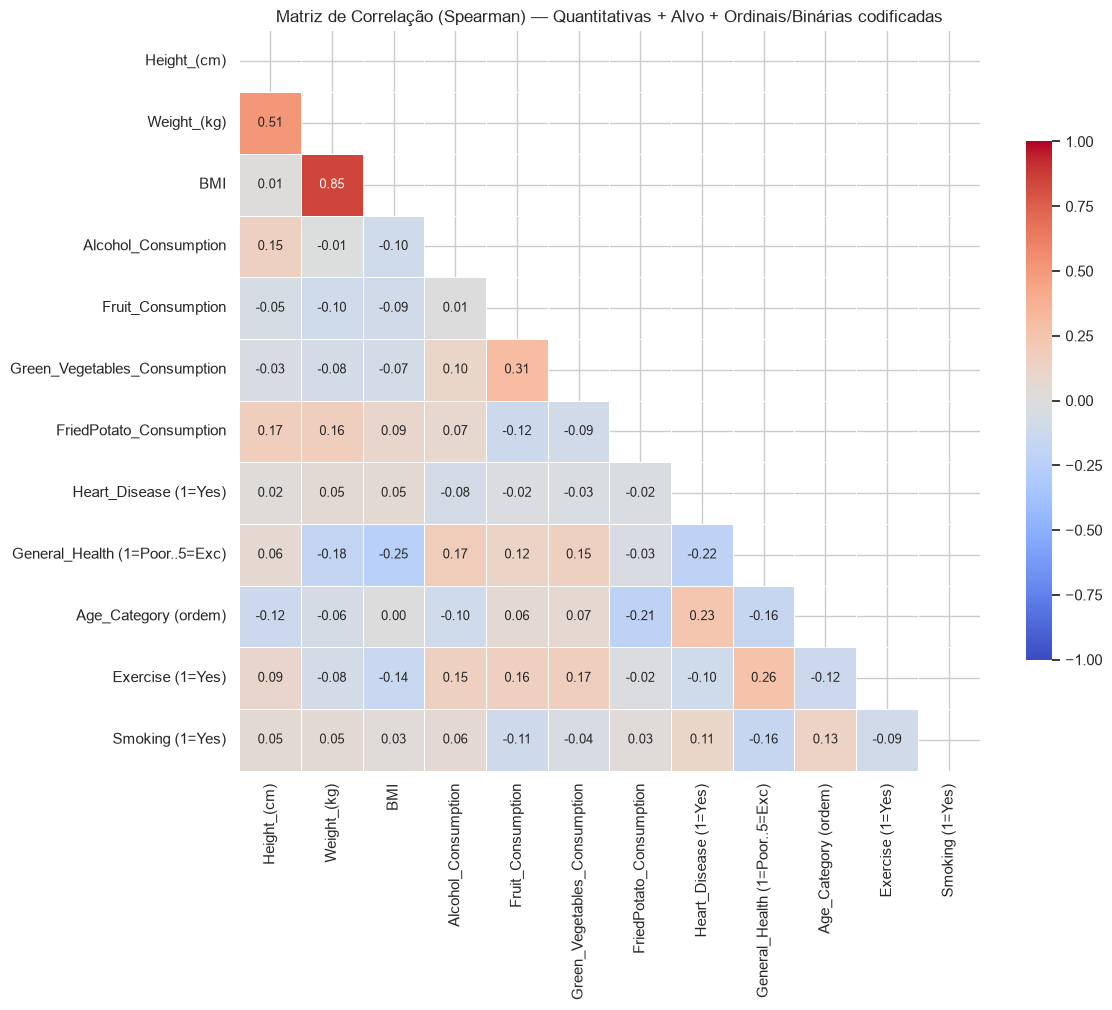

Age_Category (ordem)              0.235
General_Health (1=Poor..5=Exc)   -0.216
Smoking (1=Yes)                   0.108
Exercise (1=Yes)                 -0.096
Alcohol_Consumption              -0.075
Weight_(kg)                       0.052
BMI                               0.050
Green_Vegetables_Consumption     -0.027
FriedPotato_Consumption          -0.024
Fruit_Consumption                -0.023
Height_(cm)                       0.021
Name: Heart_Disease (1=Yes), dtype: float64

In [43]:
df_cod = df[VARS_QUANT].copy()
df_cod["Heart_Disease (1=Yes)"] = (df["Heart_Disease"] == "Yes").astype(int)
df_cod["General_Health (1=Poor..5=Exc)"] = df["General_Health"].cat.codes + 1
df_cod["Age_Category (ordem)"] = df["Age_Category"].cat.codes + 1
df_cod["Exercise (1=Yes)"] = (df["Exercise"] == "Yes").astype(int)
df_cod["Smoking (1=Yes)"] = (df["Smoking_History"] == "Yes").astype(int)

corr_multi = df_cod.corr(method="spearman")
mask_multi = np.triu(np.ones_like(corr_multi, dtype=bool))

plt.figure(figsize=(12, 10))
sns.heatmap(corr_multi, mask=mask_multi, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            square=True, linewidths=0.5, annot_kws={"size": 9}, cbar_kws={"shrink": 0.7})
plt.title("Matriz de Correlação (Spearman) — Quantitativas + Alvo + Ordinais/Binárias codificadas")
plt.tight_layout()
plt.show()

corr_multi["Heart_Disease (1=Yes)"].drop("Heart_Disease (1=Yes)").sort_values(key=abs, ascending=False).round(3)

**Como interpretar:**


*   |r| < 0.3 ~ fraca,
*   0.3 < |r| < 0.7 ~ moderada,
*  |r| > 0.7 ~ forte.

Alguma correlação chama atenção por ser forte o suficiente pra sugerir redundância entre variáveis?

*Resposta*: A única correlação **forte** é **Weight × BMI (~0,86)**, o que indica **redundância**: num modelo, provavelmente basta manter uma das duas (ou BMI + Height). Com o alvo codificado, os maiores |ρ| com `Heart_Disease` são **idade (+)** e **saúde geral (−, quanto melhor a saúde, menos doença)**, ambos fracos em valor absoluto (~0,2), mas bem acima das variáveis de consumo, que ficam perto de zero. Isso confirma o que vimos nos gráficos: **idade e estado geral de saúde dizem muito mais sobre doença cardíaca do que hábitos alimentares autorreportados**. Também aparece `General_Health` × `Exercise` (+): quem se exercita se avalia mais saudável.

*Nota:* o ρ de Spearman com uma variável binária é só uma aproximação (o ideal seria o ponto-bisserial), mas serve bem para ranquear quem se associa mais ao alvo.

##### Correlograma

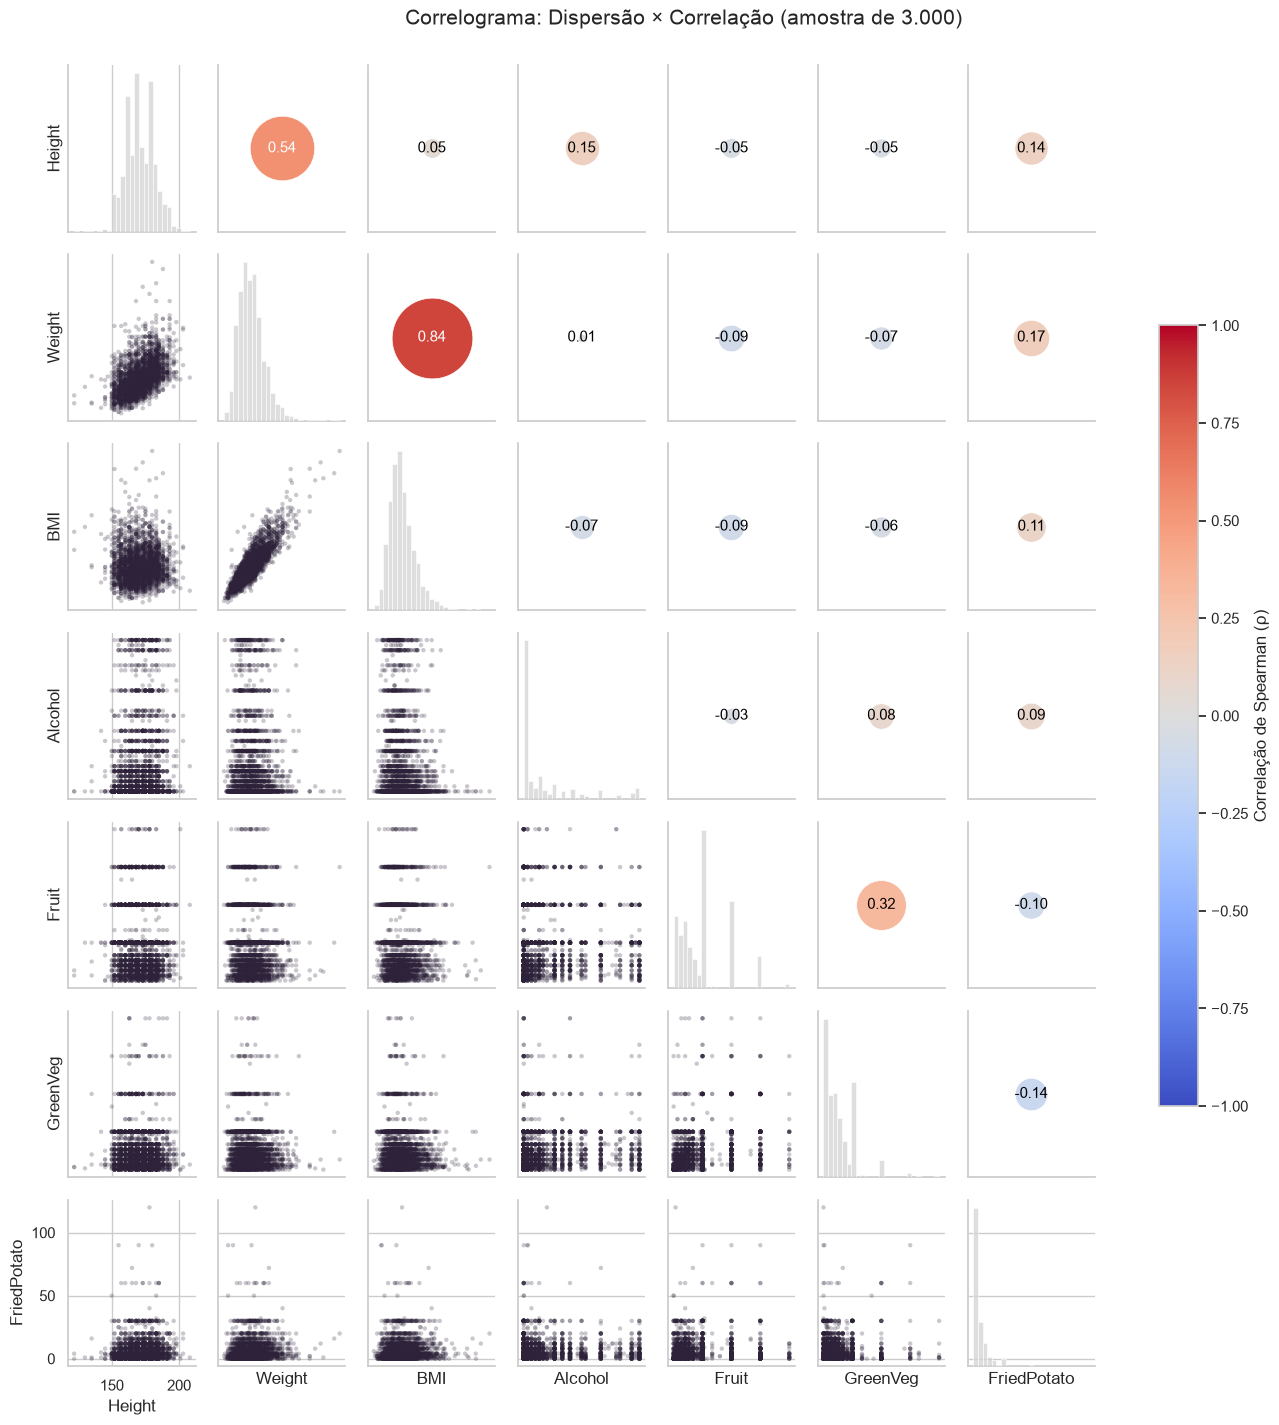

In [44]:
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

def circulo_correlacao(x, y, **kwargs):
    r = stats.spearmanr(x, y)[0]
    ax = plt.gca()
    ax.scatter([0.5], [0.5], s=abs(r) * 4000, c=[r], cmap="coolwarm", vmin=-1, vmax=1,
               transform=ax.transAxes, edgecolor="white", linewidth=0.5)
    ax.annotate(f"{r:.2f}", xy=(0.5, 0.5), xycoords=ax.transAxes, ha="center", va="center",
                fontsize=11, color="white" if abs(r) > 0.5 else "black")
    ax.set_xticks([]); ax.set_yticks([])
    ax.grid(False)

amostra_pg = df[VARS_QUANT].sample(3000, random_state=SEED)
amostra_pg.columns = ROTULOS_CORR

g = sns.PairGrid(amostra_pg, diag_sharey=False, height=2)
g.map_lower(sns.scatterplot, color=COR_DESTAQUE, alpha=0.25, s=10, edgecolor="none")
g.map_diag(sns.histplot, color=COR_NEUTRA, bins=25)
g.map_upper(circulo_correlacao)

sm = ScalarMappable(norm=Normalize(-1, 1), cmap="coolwarm")
sm.set_array([])
g.figure.colorbar(sm, ax=g.axes, shrink=0.6, label="Correlação de Spearman (ρ)")
g.figure.suptitle("Correlograma: Dispersão × Correlação (amostra de 3.000)", y=1.02, fontsize=15)
plt.show()

## Hands-on!

Agora é a vez de você realizar uma EDA com os seu conjunto de dados recebidos.

Para isso crie um novo notebook e vamos fazer **em sala** uma EDA seguindo a aula prática que acabamos de ter. Os tópicos desenvolvidos são referências.

Para esse exercício é de suma importância que vocês **elaborem perguntas** e **discutam** os resultados obtidos. Por exemplo, se houver dados faltantes, busque *entender* o porquê e *justifique* sua decisão.

Após o desenvolvimento da EDA em si, é necessário fazer uma síntese considerando:


1.   Principais conclusões em 3 a 5 pontos
2.   Declaração de Uso de IA (Ferramenta utilizada, Para o que foi aplicada e o que foi aceito/modificado/rejeitado e por quê)

O **entregável** será um notebook `ipynb`que trará todo o código, discussão, principais conclusões e declaração de uso de IA.




In [45]:
df.to_csv("../data/clean/dataset.csv", index=False)

In [46]:
diab = df["Diabetes"] == "Yes"
cardio = df["Heart_Disease"] == "Yes"
obeso = df["BMI"] >= 30
exercita = df["Exercise"] == "Yes"
fumante = df["Smoking_History"] == "Yes"

print(f"Diabetes entre obesos: {diab[obeso].mean():.1%} | não obesos: {diab[~obeso].mean():.1%}")
print(f"Diabetes sem exercício: {diab[~exercita].mean():.1%} | com exercício: {diab[exercita].mean():.1%}")
print(f"Doença cardíaca com tabagismo: {cardio[fumante].mean():.1%} | sem: {cardio[~fumante].mean():.1%}")

categoria_imc = pd.cut(df["BMI"], [0, 18.5, 25, 30, 200], right=False,
                       labels=["Abaixo do peso", "Normal", "Sobrepeso", "Obesidade"])
df.groupby(categoria_imc, observed=True)[["Diabetes", "Heart_Disease"]].agg(lambda s: (s == "Yes").mean())

Diabetes entre obesos: 21.2% | não obesos: 8.8%
Diabetes sem exercício: 21.9% | com exercício: 10.4%
Doença cardíaca com tabagismo: 11.6% | sem: 5.7%


,Diabetes,Heart_Disease
BMI,,
Abaixo do peso,0.046931,0.075178
Normal,0.058964,0.061996
Sobrepeso,0.113619,0.082043
Obesidade,0.211695,0.096098
